# Farm Animal Activity Recognition — YOLO11 on CBVD-5 (Training only)

**Pipeline:** CBVD-5 (AVA-format annotations) → YOLO format → leakage-safe split by video → YOLO11s fine-tuning → validation + test evaluation → `best.pt`

**Before you click "Run All" on Kaggle:**
1. *Add Input* → search **`cbvd-5cow-behavior-video-dataset`** (by fandaoerji) and add it.
2. *Settings* → **Accelerator: GPU T4 x2 or P100** (only one GPU is used).
3. *Settings* → **Internet: ON** (needed for `pip install ultralytics` and downloading `yolo11s.pt`).

**What the dataset actually contains** (from the CBVD-5 paper, Sci. Rep. 2024):
- Folders: `videos/` (raw hour-long footage), `video_cut/` (687 ten-second clips), `rawframes/` (all extracted frames), `labelframes/` (keyframes that were annotated), `annotations/` (AVA-style CSVs + action list `.pbtxt`).
- Each CSV row is: `video_id, keyframe_timestamp_sec, x1, y1, x2, y2 (normalized 0-1), action_id, target_id`.
- **One cow box can have several labels** (e.g. *lying + rumination*, *standing + drinking*). YOLO allows only one class per box, so this notebook merges rows of the same box and picks **one** label using a priority order (state behaviours before posture). You can change the order in the config cell.

The notebook **auto-detects** the folder paths, the action-ID → class mapping, and how timestamps map to image files, and prints everything so you can verify it.

In [1]:
!nvidia-smi
!pip install -q -U ultralytics

Tue Oct  6 18:18:40 2026       
+-----------------------------------------------------------------------------------------+
| NVIDIA-SMI 580.178.04             Driver Version: 580.178.04     CUDA Version: 13.0     |
+-----------------------------------------+------------------------+----------------------+
| GPU  Name                 Persistence-M | Bus-Id          Disp.A | Volatile Uncorr. ECC |
| Fan  Temp   Perf          Pwr:Usage/Cap |           Memory-Usage | GPU-Util  Compute M. |
|                                         |                        |               MIG M. |
|=========================================+========================+======================|
|   0  Tesla T4                       Off |   00000000:00:04.0 Off |                    0 |
| N/A   46C    P8             12W /   70W |       0MiB /  15360MiB |      0%      Default |
|                                         |                        |                  N/A |
+-----------------------------------------+-----

## 1. Configuration

In [2]:
import os, re, json, shutil, random, warnings
from pathlib import Path
from collections import defaultdict, Counter

import numpy as np
import pandas as pd
import cv2
import yaml
import matplotlib.pyplot as plt
from PIL import Image
from IPython.display import display, Image as IPyImage

warnings.filterwarnings("ignore", category=UserWarning)

SEED = 42
random.seed(SEED); np.random.seed(SEED)

# ---------------- Paths ----------------
INPUT_ROOT  = "/kaggle/input/datasets/fandaoerji/cbvd-5cow-behavior-video-dataset"        # Kaggle mounts datasets here
DATA_ROOT   = None                   # None = auto-detect. Or set e.g. "/kaggle/input/cbvd-5cow-behavior-video-dataset"
WORK_DIR    = Path("/kaggle/working")
YOLO_DIR    = WORK_DIR / "cbvd5_yolo"            # converted YOLO dataset
PROJECT_DIR = WORK_DIR / "runs" / "detect"       # -> runs/detect/cattle_behavior/
RUN_NAME    = "cattle_behavior"

# ---------------- Classes (exactly 5, fixed order) ----------------
CLASS_NAMES = ["standing", "lying", "foraging", "drinking", "rumination"]

# Keywords used to map the names in the dataset's action-list .pbtxt to our 5 classes
CLASS_KEYWORDS = {
    "standing":   ["stand"],
    "lying":      ["lying", "lie", "lay", "recumb"],
    "foraging":   ["forag", "feed", "eat", "graz"],
    "drinking":   ["drink", "water"],
    "rumination": ["rumin", "chew"],
}
# If auto-mapping fails, fill this manually, e.g. {1: "standing", 2: "lying", 3: "foraging", 4: "drinking", 5: "rumination"}
MANUAL_ACTION_ID_MAP = None

# A box can have several labels (e.g. lying + rumination). YOLO needs ONE class per box.
# The first class in this list that is present on the box wins.
# State behaviours first, otherwise foraging/drinking/rumination would disappear (they always co-occur with a posture).
LABEL_PRIORITY = ["drinking", "foraging", "rumination", "lying", "standing"]

# ---------------- Split ----------------
SPLIT_RATIOS = (0.70, 0.15, 0.15)   # train / val / test, split BY VIDEO (no leakage between adjacent frames)
GROUP_REGEX  = None                 # optional: regex with one capture group to group clips from the same source video,
                                    # e.g. r"^(.*)_\d+$". None = each video_id is its own group.

# ---------------- Training ----------------
MODEL_NAME = "yolo11s.pt"   # switch to "yolo11m.pt" if GPU memory allows (then use BATCH = 8)
EPOCHS     = 100
IMGSZ      = 640            # try 960 later if cows are small in the frame
BATCH      = 16             # -1 = Ultralytics auto-batch
PATIENCE   = 25             # early stopping
WORKERS    = 4

IMG_EXT  = {".jpg", ".jpeg", ".png", ".bmp"}
VID_EXT  = {".mp4", ".avi", ".mov", ".mkv"}
BIG_DIRS = {"rawframes", "labelframes", "videos", "video_cut"}   # not descended into while searching

## 2. Locate the dataset and inspect its directory structure

In [3]:
def walk_pruned(root, max_depth=6):
    # os.walk that never descends into the huge frame/video folders (they are still listed)
    root = Path(root)
    for cur, dirs, files in os.walk(root):
        depth = len(Path(cur).relative_to(root).parts)
        if depth >= max_depth:
            dirs[:] = []
        yield Path(cur), list(dirs), files
        dirs[:] = [d for d in dirs if d.lower() not in BIG_DIRS]

def locate_dataset():
    if DATA_ROOT:
        root = Path(DATA_ROOT)
        for cur, dirs, files in walk_pruned(root):
            for d in dirs:
                if d.lower() == "annotations":
                    return root, cur / d
        return root, root
    for cur, dirs, files in walk_pruned(INPUT_ROOT):
        for d in dirs:
            if d.lower() == "annotations":
                return cur, cur / d
    for cur, dirs, files in walk_pruned(INPUT_ROOT):          # fallback: CSVs not inside "annotations/"
        if any(f.lower().endswith(".csv") and "ava" in f.lower() for f in files):
            return cur.parent, cur
    raise FileNotFoundError("Could not find the CBVD-5 annotations under /kaggle/input. "
                            "Did you add the dataset? Otherwise set DATA_ROOT manually.")

def find_sub(root, name):
    for cur, dirs, files in walk_pruned(root, max_depth=4):
        for d in dirs:
            if d.lower() == name:
                return cur / d
    return None

def show_tree(path, max_depth=2, max_items=6, prefix=""):
    path = Path(path)
    try:
        entries = sorted(os.scandir(path), key=lambda e: (not e.is_dir(), e.name))
    except (PermissionError, FileNotFoundError):
        return
    dirs  = [e for e in entries if e.is_dir()]
    files = [e for e in entries if e.is_file()]
    print(f"{prefix}{path.name}/   [{len(dirs)} dirs, {len(files)} files]")
    if max_depth == 0:
        return
    for e in files[:max_items]:
        print(f"{prefix}    {e.name}   ({e.stat().st_size/1e6:.2f} MB)")
    if len(files) > max_items:
        print(f"{prefix}    ... +{len(files)-max_items} more files")
    for e in dirs[:max_items]:
        show_tree(e.path, max_depth - 1, max_items, prefix + "    ")
    if len(dirs) > max_items:
        print(f"{prefix}    ... +{len(dirs)-max_items} more dirs")

ROOT, ANN_DIR = locate_dataset()
LF_DIR    = find_sub(ROOT, "labelframes")
RAW_DIR   = find_sub(ROOT, "rawframes")
CUT_DIR   = find_sub(ROOT, "video_cut")
VIDEO_DIR = find_sub(ROOT, "videos")

print("Dataset root :", ROOT)
print("annotations  :", ANN_DIR)
print("labelframes  :", LF_DIR)
print("rawframes    :", RAW_DIR)
print("video_cut    :", CUT_DIR)
print("videos       :", VIDEO_DIR)
print("\n================ Directory tree (truncated) ================")
show_tree(ROOT, max_depth=3)

Dataset root : /kaggle/input/datasets/fandaoerji/cbvd-5cow-behavior-video-dataset
annotations  : /kaggle/input/datasets/fandaoerji/cbvd-5cow-behavior-video-dataset/annotations
labelframes  : /kaggle/input/datasets/fandaoerji/cbvd-5cow-behavior-video-dataset/labelframes
rawframes    : None
video_cut    : None
videos       : /kaggle/input/datasets/fandaoerji/cbvd-5cow-behavior-video-dataset/videos

================ Directory tree (truncated) ================
cbvd-5cow-behavior-video-dataset/   [8 dirs, 1 files]
    CBVD-5.csv   (2.41 MB)
    annotations/   [0 dirs, 11 files]
        ava_action_list_v2.1_for_activitynet_2018.pbtxt   (0.00 MB)
        ava_dense_proposals_test.FAIR.recall_93.9.pkl   (0.11 MB)
        ava_dense_proposals_train.FAIR.recall_93.9.pkl   (1.04 MB)
        ava_dense_proposals_val.FAIR.recall_93.9.pkl   (0.11 MB)
        ava_test_excluded_timestamps_v2.1.csv   (0.00 MB)
        ava_test_v2.1.csv   (0.64 MB)
        ... +5 more files
    labelframes/   [1 dirs, 0 fi

In [4]:
# ---- Inspect every annotation file ----
ann_files = sorted(p for p in Path(ANN_DIR).rglob("*") if p.is_file())
for p in ann_files:
    print(f"\n### {p.name}   ({p.stat().st_size/1e3:.1f} KB)")
    if p.suffix.lower() in {".csv", ".txt", ".pbtxt"}:
        with open(p, "r", errors="ignore") as f:
            for i, line in enumerate(f):
                if i >= 6: print("   ..."); break
                print("  ", line.rstrip()[:160])
    else:
        print("   (binary file — e.g. cached proposals .pkl, not needed for YOLO)")


### ava_action_list_v2.1_for_activitynet_2018.pbtxt   (0.4 KB)
   label {
     name: "stand"
     label_id: 1
     label_type: PERSON_MOVEMENT
   }
   label {
   ...

### ava_dense_proposals_test.FAIR.recall_93.9.pkl   (114.5 KB)
   (binary file — e.g. cached proposals .pkl, not needed for YOLO)

### ava_dense_proposals_train.FAIR.recall_93.9.pkl   (1042.0 KB)
   (binary file — e.g. cached proposals .pkl, not needed for YOLO)

### ava_dense_proposals_val.FAIR.recall_93.9.pkl   (114.5 KB)
   (binary file — e.g. cached proposals .pkl, not needed for YOLO)

### ava_test_excluded_timestamps_v2.1.csv   (0.0 KB)

### ava_test_v2.1.csv   (638.9 KB)
   393,4,0.33001313541666666,0.23044351851851852,0.417415625,0.36575092592592595,2,1
   393,4,0.33001313541666666,0.23044351851851852,0.417415625,0.36575092592592595,5,1
   393,4,0.3056291666666667,0.19978888888888888,0.37995520833333335,0.3002111111111111,2,1
   393,4,0.3056291666666667,0.19978888888888888,0.37995520833333335,0.3002111111111111,5

## 3. Map dataset action IDs → our 5 classes

In [5]:
def parse_action_list(files):
    cands = [p for p in files if ("action" in p.name.lower() and "list" in p.name.lower())
             or ".pbtxt" in p.name.lower()]
    for p in cands:
        text = p.read_text(errors="ignore")
        pairs = []
        for block in re.findall(r"\{([^{}]*)\}", text):
            n = re.search(r'name\s*:\s*"([^"]+)"', block)
            i = re.search(r"\b(?:label_id|id)\s*:\s*(\d+)", block)
            if n and i:
                pairs.append((int(i.group(1)), n.group(1)))
        if pairs:
            return p, pairs
    return None, []

def keyword_class(name):
    low = name.lower()
    hits = [c for c, kws in CLASS_KEYWORDS.items() if any(k in low for k in kws)]
    return hits[0] if len(hits) == 1 else None

if MANUAL_ACTION_ID_MAP:
    ACTION_ID_TO_CLASS = {int(k): v for k, v in MANUAL_ACTION_ID_MAP.items()}
    print("Using MANUAL_ACTION_ID_MAP")
else:
    pb_file, pairs = parse_action_list(ann_files)
    print("Action list file:", pb_file)
    ACTION_ID_TO_CLASS = {}
    for aid, name in pairs:
        cls = keyword_class(name)
        print(f"  action_id {aid:>3}  name='{name}'  ->  {cls}")
        if cls: ACTION_ID_TO_CLASS[aid] = cls

assert set(ACTION_ID_TO_CLASS.values()) <= set(CLASS_NAMES)
missing = set(CLASS_NAMES) - set(ACTION_ID_TO_CLASS.values())
if missing:
    raise ValueError(f"No action id mapped to {missing}. Look at the printout above and set MANUAL_ACTION_ID_MAP.")
CLASS_TO_ID = {c: i for i, c in enumerate(CLASS_NAMES)}
print("\nFinal mapping:", ACTION_ID_TO_CLASS)

Action list file: /kaggle/input/datasets/fandaoerji/cbvd-5cow-behavior-video-dataset/annotations/ava_action_list_v2.1_for_activitynet_2018.pbtxt
  action_id   1  name='stand'  ->  standing
  action_id   2  name='lying down'  ->  lying
  action_id   3  name='foraging'  ->  foraging
  action_id   4  name='drinking water'  ->  drinking
  action_id   5  name='rumination'  ->  rumination

Final mapping: {1: 'standing', 2: 'lying', 3: 'foraging', 4: 'drinking', 5: 'rumination'}


## 4. Load AVA-format annotation CSVs

In [6]:
COLS = ["video_id", "ts", "x1", "y1", "x2", "y2", "action_id", "entity_id"]

def read_ava_csv(path):
    df = pd.read_csv(path, header=None, dtype=str, skipinitialspace=True)
    try:
        float(df.iloc[0, 1])
    except ValueError:                       # file has a header row
        df = df.iloc[1:].reset_index(drop=True)
    if df.shape[1] < 7:
        print(f"  skip {path.name}: only {df.shape[1]} columns")
        return None
    df = df.iloc[:, :8]
    df.columns = COLS[:df.shape[1]]
    df["video_id"] = df["video_id"].str.strip()
    for c in ["ts", "x1", "y1", "x2", "y2"]:
        df[c] = pd.to_numeric(df[c], errors="coerce")
    df["action_id"] = pd.to_numeric(df["action_id"], errors="coerce")
    df["source_csv"] = path.name
    return df.dropna(subset=["ts", "x1", "y1", "x2", "y2", "action_id"])

label_csvs = [p for p in ann_files if p.suffix.lower() == ".csv"
              and "exclud" not in p.name.lower() and "proposal" not in p.name.lower()]
frames_list = []
for p in label_csvs:
    d = read_ava_csv(p)
    if d is not None:
        print(f"  {p.name}: {len(d):,} rows, {d.video_id.nunique()} videos")
        frames_list.append(d)
ann = pd.concat(frames_list, ignore_index=True)
ann["action_id"] = ann["action_id"].astype(int)
ann["ts"] = ann["ts"].round(3)
n0 = len(ann)
ann = ann.drop_duplicates(subset=["video_id", "ts", "x1", "y1", "x2", "y2", "action_id"])
print(f"\nTotal rows: {n0:,}  (after removing duplicates: {len(ann):,})")

# Excluded timestamps (problematic frames listed by the authors)
excl = [p for p in ann_files if "exclud" in p.name.lower() and p.suffix.lower() == ".csv"]
for p in excl:
    try:
        e = pd.read_csv(p, header=None, dtype={0: str})
        if len(e):
            bad = set(zip(e[0].astype(str).str.strip(), pd.to_numeric(e[1], errors="coerce").round(3)))
            before = len(ann)
            ann = ann[~pd.Series(list(zip(ann.video_id, ann.ts)), index=ann.index).isin(bad)]
            print(f"Excluded-timestamps file {p.name}: removed {before-len(ann)} rows")
    except pd.errors.EmptyDataError:
        print(f"Excluded-timestamps file {p.name} is empty")

print("\nRaw action_id counts:")
print(ann.action_id.value_counts().sort_index().rename(index=lambda i: f"{i} ({ACTION_ID_TO_CLASS.get(i, 'UNMAPPED')})"))
unmapped = ~ann.action_id.isin(ACTION_ID_TO_CLASS)
if unmapped.any():
    print(f"Dropping {unmapped.sum()} rows with unmapped action ids")
ann = ann[~unmapped].copy()
ann["cls_name"] = ann.action_id.map(ACTION_ID_TO_CLASS)
print("\nCoordinate ranges:", ann[["x1", "y1", "x2", "y2"]].agg(["min", "max"]).round(3).to_dict())
print("Timestamp range:", ann.ts.min(), "->", ann.ts.max())
print("Example video ids:", ann.video_id.drop_duplicates().head(5).tolist())

  ava_test_v2.1.csv: 7,522 rows, 50 videos
  ava_train_v2.1.csv: 34,102 rows, 492 videos
  ava_val_v2.1.csv: 3,761 rows, 50 videos

Total rows: 45,385  (after removing duplicates: 38,781)
Excluded-timestamps file ava_test_excluded_timestamps_v2.1.csv is empty
Excluded-timestamps file ava_train_excluded_timestamps_v2.1.csv is empty
Excluded-timestamps file ava_val_excluded_timestamps_v2.1.csv is empty

Raw action_id counts:
action_id
1 (standing)      16194
2 (lying)          9736
3 (foraging)       5914
4 (drinking)        764
5 (rumination)     6173
Name: count, dtype: int64

Coordinate ranges: {'x1': {'min': 0.0, 'max': 5.261}, 'y1': {'min': 0.0, 'max': 1.945}, 'x2': {'min': 0.026, 'max': 5.409}, 'y2': {'min': 0.074, 'max': 2.276}}
Timestamp range: 2 -> 7
Example video ids: ['393', '392', '391', '390', '389']


## 5. Merge multi-label boxes → one class per box

Each AVA row is (box, one action). The same cow box appears in several rows when it has several behaviours. We group rows by identical box, look at the label combinations, then pick one class with `LABEL_PRIORITY`.

In [7]:
for c in ["x1", "y1", "x2", "y2"]:
    ann[c + "_r"] = ann[c].round(3)

boxes = (ann.groupby(["video_id", "ts", "x1_r", "y1_r", "x2_r", "y2_r"])["cls_name"]
            .agg(lambda s: tuple(sorted(set(s)))).reset_index()
            .rename(columns={"cls_name": "labels", "x1_r": "x1", "y1_r": "y1", "x2_r": "x2", "y2_r": "y2"}))

print(f"Unique boxes: {len(boxes):,}   unique keyframes: {boxes[['video_id','ts']].drop_duplicates().shape[0]:,}")
print("\nLabel combinations per box (this is why a priority rule is needed):")
display(pd.Series(Counter(" + ".join(l) for l in boxes.labels)).sort_values(ascending=False).rename("boxes").to_frame())

def pick_label(labels):
    for c in LABEL_PRIORITY:
        if c in labels:
            return c
    return None

boxes["cls_name"] = boxes.labels.apply(pick_label)
boxes["cls_id"] = boxes.cls_name.map(CLASS_TO_ID)

raw_counts = Counter(c for labs in boxes.labels for c in labs)
final_counts = boxes.cls_name.value_counts()
display(pd.DataFrame({"boxes having this label": pd.Series(raw_counts),
                      "boxes assigned to it (final)": final_counts}).reindex(CLASS_NAMES).fillna(0).astype(int))

Unique boxes: 25,324   unique keyframes: 3,199

Label combinations per box (this is why a priority rule is needed):


,boxes
standing,8272
foraging + standing,5676
lying + rumination,4955
lying,4505
rumination + standing,1124
drinking + standing,738
foraging + lying,33
lying + standing,13
drinking,6
foraging,2


,boxes having this label,boxes assigned to it (final)
standing,15823,8272
lying,9506,4518
foraging,5711,5711
drinking,744,744
rumination,6079,6079


## 6. Find the image file for every annotated keyframe

The annotation stores `(video_id, timestamp_in_seconds)`, not a filename. The notebook tries several timestamp→frame-number rules on `labelframes/` first, then `rawframes/`, and keeps the rule that finds the most files. If neither works it extracts the frames from `video_cut/` videos with OpenCV.

In [8]:
def trailing_int(s):
    m = re.search(r"(\d+)$", s)
    return int(m.group(1)) if m else None

def build_frame_index(root, known_vids):
    # vid -> {frame_number: path}. Handles <root>/<vid>/<anything>_<num>.jpg and <root>/<vid>_<num>.jpg
    idx = defaultdict(dict)
    known = set(known_vids)
    for cur, dirs, files in os.walk(root):
        parent = Path(cur).name
        for f in files:
            stem, ext = os.path.splitext(f)
            if ext.lower() not in IMG_EXT:
                continue
            vid, num = None, None
            if parent in known:
                vid, num = parent, trailing_int(stem)
            elif "_" in stem:
                v, n = stem.rsplit("_", 1)
                if n.isdigit():
                    vid, num = v, int(n)
            if vid is not None and num is not None:
                idx[vid][num] = os.path.join(cur, f)
    return idx

def best_mapping(idx, keyframes, fps_guess):
    # Try num = round((ts - t0) * fps) + off, plus a rank-order rule.
    # Ties are common in rawframes/ (every frame exists), so we break them by preferring
    # fps closest to the folder's real frame rate (= frames per clip / 10 s), then t0=0, then off=1 (mmaction2 style).
    if not idx:
        return 0.0, None
    t0s = sorted({0.0, 1.0, float(keyframes.ts.min())})
    fpss = sorted({1, 25, 30, max(1, int(round(fps_guess)))})
    total = len(keyframes)
    scored = []
    for fps in fpss:
        for t0 in t0s:
            for off in (0, 1):
                hits = sum(1 for v, t in zip(keyframes.video_id, keyframes.ts)
                           if int(round((t - t0) * fps)) + off in idx.get(v, {}))
                tie = (-abs(fps - fps_guess), -t0, off if fps > 1 else -off)
                scored.append((hits / total, tie, ("formula", fps, t0, off)))
    # rank rule: k-th annotated timestamp of a video <-> k-th image of that video (only if counts match)
    hits = sum(len(g) for v, g in keyframes.groupby("video_id") if v in idx and len(idx[v]) == g.ts.nunique())
    scored.append((hits / total - 1e-9, (-1e9, 0, 0), ("rank",)))
    scored.sort(key=lambda x: (x[0], x[1]), reverse=True)
    top = scored[0]
    n_tied = sum(1 for x in scored if abs(x[0] - top[0]) < 1e-12)
    if n_tied > 1:
        print(f"  note: {n_tied} rules reach the same hit rate; chose the one matching ~{fps_guess:.1f} fps. "
              f"Verify with the visual check in section 9.")
    return top[0], top[2]

def resolve(idx, keyframes, rule):
    out = {}
    if rule[0] == "formula":
        _, fps, t0, off = rule
        for v, t in zip(keyframes.video_id, keyframes.ts):
            p = idx.get(v, {}).get(int(round((t - t0) * fps)) + off)
            if p: out[(v, t)] = p
    else:
        for v, g in keyframes.groupby("video_id"):
            if v in idx and len(idx[v]) == g.ts.nunique():
                for t, n in zip(sorted(g.ts.unique()), sorted(idx[v])):
                    out[(v, t)] = idx[v][n]
    return out

keyframes = boxes[["video_id", "ts"]].drop_duplicates().reset_index(drop=True)
ann_vids = set(keyframes.video_id)
resolved, sources = {}, []

for name, d in [("labelframes", LF_DIR), ("rawframes", RAW_DIR)]:
    if d is None or len(resolved) == len(keyframes):
        continue
    print(f"Indexing {name} ... (rawframes can take a few minutes)")
    idx = build_frame_index(d, ann_vids)
    common = ann_vids & set(idx)
    print(f"  {sum(len(v) for v in idx.values()):,} images, {len(idx)} video ids, {len(common)} match annotation ids")
    if not common:
        print("  sample index ids:", list(idx)[:3], " sample annotation ids:", list(ann_vids)[:3])
        continue
    fps_guess = np.median([len(v) for v in idx.values()]) / 10.0      # clips are 10 s long
    print(f"  ~{fps_guess:.1f} images per second of video in this folder")
    rate, rule = best_mapping(idx, keyframes, fps_guess)
    print(f"  best rule: {rule}  ->  {rate:.1%} of keyframes found")
    if rate > 0:
        new = {k: p for k, p in resolve(idx, keyframes, rule).items() if k not in resolved}
        resolved.update(new)
        sources.append((name, rule, len(new)))

def extract_from_videos(video_dir, keyframes, out_dir):
    out_dir.mkdir(parents=True, exist_ok=True)
    vids = {p.stem: p for p in Path(video_dir).rglob("*") if p.suffix.lower() in VID_EXT}
    t0 = 0.0 if keyframes.ts.max() <= 11 else float(keyframes.ts.min())
    out = {}
    for v, g in keyframes.groupby("video_id"):
        if v not in vids: continue
        cap = cv2.VideoCapture(str(vids[v]))
        fps = cap.get(cv2.CAP_PROP_FPS) or 25
        for t in sorted(g.ts):
            cap.set(cv2.CAP_PROP_POS_FRAMES, int(round((t - t0) * fps)))
            ok, frame = cap.read()
            if ok:
                p = out_dir / f"{re.sub(r'[^A-Za-z0-9_-]', '_', v)}__{t:g}.jpg"
                cv2.imwrite(str(p), frame)
                out[(v, t)] = str(p)
        cap.release()
    return out

if len(resolved) < 0.5 * len(keyframes) and (CUT_DIR or VIDEO_DIR):
    print("Too few frames found on disk -> extracting keyframes from video clips with OpenCV ...")
    missing_kf = keyframes[[(v, t) not in resolved for v, t in zip(keyframes.video_id, keyframes.ts)]]
    new = extract_from_videos(CUT_DIR or VIDEO_DIR, missing_kf, WORK_DIR / "_extracted_frames")
    resolved.update(new)
    sources.append(("video extraction", None, len(new)))

print("\nSources used:", sources)
print(f"Keyframes with an image: {len(resolved):,} / {len(keyframes):,} ({len(resolved)/len(keyframes):.1%})")
if not resolved:
    raise RuntimeError("No images matched the annotations. Look at the directory tree / sample ids above "
                       "and adjust build_frame_index().")

Indexing labelframes ... (rawframes can take a few minutes)
  4,122 images, 687 video ids, 537 match annotation ids
  ~0.6 images per second of video in this folder
  note: 2 rules reach the same hit rate; chose the one matching ~0.6 fps. Verify with the visual check in section 9.
  best rule: ('formula', 1, 0.0, 0)  ->  100.0% of keyframes found

Sources used: [('labelframes', ('formula', 1, 0.0, 0), 3199)]
Keyframes with an image: 3,199 / 3,199 (100.0%)


## 7. Convert boxes to YOLO format

In [9]:
boxes["key"] = list(zip(boxes.video_id, boxes.ts))
boxes = boxes[boxes.key.isin(resolved)].copy()

# CBVD-5 coordinates are normalized (0-1). A few annotation rows are broken
# (values up to ~5), so drop boxes clearly outside the image and clip tiny overshoots.
coords = boxes[["x1", "y1", "x2", "y2"]]
bad = (coords > 1.05).any(axis=1) | (coords < -0.05).any(axis=1)
print(f"Broken boxes (outside image) dropped: {bad.sum()} of {len(boxes)}")
display(boxes[bad][["video_id", "ts", "x1", "y1", "x2", "y2", "cls_name"]].head())
boxes = boxes[~bad]

records = defaultdict(list)   # key -> [(cls, xc, yc, w, h)]
dropped = 0
for r in boxes.itertuples():
    x1, x2 = sorted((min(max(r.x1, 0), 1), min(max(r.x2, 0), 1)))
    y1, y2 = sorted((min(max(r.y1, 0), 1), min(max(r.y2, 0), 1)))
    w, h = x2 - x1, y2 - y1
    if w < 0.003 or h < 0.003:
        dropped += 1
        continue
    records[r.key].append((int(r.cls_id), x1 + w / 2, y1 + h / 2, w, h))

assert records, "No boxes left — check the coordinate printout above."
print(f"Images: {len(records):,}   boxes: {sum(map(len, records.values())):,}   tiny boxes dropped: {dropped}")
print(f"Boxes per image: mean {np.mean([len(v) for v in records.values()]):.1f}, "
      f"max {max(len(v) for v in records.values())}")

Broken boxes (outside image) dropped: 2 of 25324


,video_id,ts,x1,y1,x2,y2,cls_name
11981,357,7,0.194,1.945,0.463,2.276,foraging
11989,357,7,5.261,0.247,5.409,0.683,foraging


Images: 3,199   boxes: 25,320   tiny boxes dropped: 2
Boxes per image: mean 7.9, max 24


## 8. Train / validation / test split **by video** (no leakage)

All keyframes from one video (or one source group if `GROUP_REGEX` is set) go to the same split. `StratifiedGroupKFold` keeps the class distribution similar across splits, which matters for the rare *drinking* class.

Note: all clips come from one barn with the same 107 cows, so the test set measures generalisation to *new clips*, not to new farms.

In [10]:
from sklearn.model_selection import StratifiedGroupKFold

def group_of(vid):
    if GROUP_REGEX:
        m = re.match(GROUP_REGEX, vid)
        if m: return m.group(1)
    return vid

keys = list(records)
y, g = [], []
for k in keys:
    for b in records[k]:
        y.append(b[0]); g.append(group_of(k[0]))

n_groups = len(set(g))
n_splits = min(20, n_groups)
sgkf = StratifiedGroupKFold(n_splits=n_splits, shuffle=True, random_state=SEED)
fold_of = {}
for f, (_, te) in enumerate(sgkf.split(np.zeros(len(y)), y, g)):
    for i in te:
        fold_of[g[i]] = f

n_test = max(1, round(n_splits * SPLIT_RATIOS[2]))
n_val  = max(1, round(n_splits * SPLIT_RATIOS[1]))
def split_of_group(grp):
    f = fold_of[grp]
    return "test" if f < n_test else "val" if f < n_test + n_val else "train"

split_of = {k: split_of_group(group_of(k[0])) for k in keys}

# leakage check
grp_split = defaultdict(set)
for k, s in split_of.items():
    grp_split[group_of(k[0])].add(s)
assert all(len(s) == 1 for s in grp_split.values()), "A video ended up in two splits!"
print(f"{n_groups} video groups, {n_splits} folds -> test folds {n_test}, val folds {n_val}. No video is shared between splits ✔")

rows = []
for s in ["train", "val", "test"]:
    ks = [k for k in keys if split_of[k] == s]
    cnt = Counter(b[0] for k in ks for b in records[k])
    rows.append({"split": s, "videos": len({k[0] for k in ks}), "images": len(ks),
                 "boxes": sum(cnt.values()), **{CLASS_NAMES[i]: cnt.get(i, 0) for i in range(len(CLASS_NAMES))}})
split_table = pd.DataFrame(rows).set_index("split")
display(split_table)
for s in ["val", "test"]:
    zero = [c for c in CLASS_NAMES if split_table.loc[s, c] == 0]
    if zero:
        print(f"WARNING: {s} has no instances of {zero} — change SEED and rerun this cell.")

537 video groups, 20 folds -> test folds 3, val folds 3. No video is shared between splits ✔


,videos,images,boxes,standing,lying,foraging,drinking,rumination
split,,,,,,,,
train,382,2278,18402,6125,3095,4236,534,4412
val,81,480,3854,1201,747,860,139,907
test,74,441,3064,946,675,612,71,760


## 9. Write the YOLO dataset and `data.yaml`

In [11]:
if YOLO_DIR.exists():
    shutil.rmtree(YOLO_DIR)
for s in ["train", "val", "test"]:
    (YOLO_DIR / "images" / s).mkdir(parents=True, exist_ok=True)
    (YOLO_DIR / "labels" / s).mkdir(parents=True, exist_ok=True)

def safe_name(vid, ts):
    return f"{re.sub(r'[^A-Za-z0-9_-]', '_', vid)}__{ts:g}".replace(".", "p")

for k in keys:
    s, src = split_of[k], resolved[k]
    stem = safe_name(*k)
    shutil.copy2(src, YOLO_DIR / "images" / s / (stem + Path(src).suffix.lower()))
    with open(YOLO_DIR / "labels" / s / (stem + ".txt"), "w") as f:
        for c, xc, yc, w, h in records[k]:
            f.write(f"{c} {xc:.6f} {yc:.6f} {w:.6f} {h:.6f}\n")

DATA_YAML = YOLO_DIR / "data.yaml"
with open(DATA_YAML, "w") as f:
    yaml.safe_dump({"path": str(YOLO_DIR), "train": "images/train", "val": "images/val", "test": "images/test",
                    "nc": len(CLASS_NAMES), "names": {i: n for i, n in enumerate(CLASS_NAMES)}},
                   f, sort_keys=False)
print(open(DATA_YAML).read())
for s in ["train", "val", "test"]:
    print(s, len(os.listdir(YOLO_DIR / "images" / s)), "images,", len(os.listdir(YOLO_DIR / "labels" / s)), "labels")

path: /kaggle/working/cbvd5_yolo
train: images/train
val: images/val
test: images/test
nc: 5
names:
  0: standing
  1: lying
  2: foraging
  3: drinking
  4: rumination

train 2278 images, 2278 labels
val 480 images, 480 labels
test 441 images, 441 labels


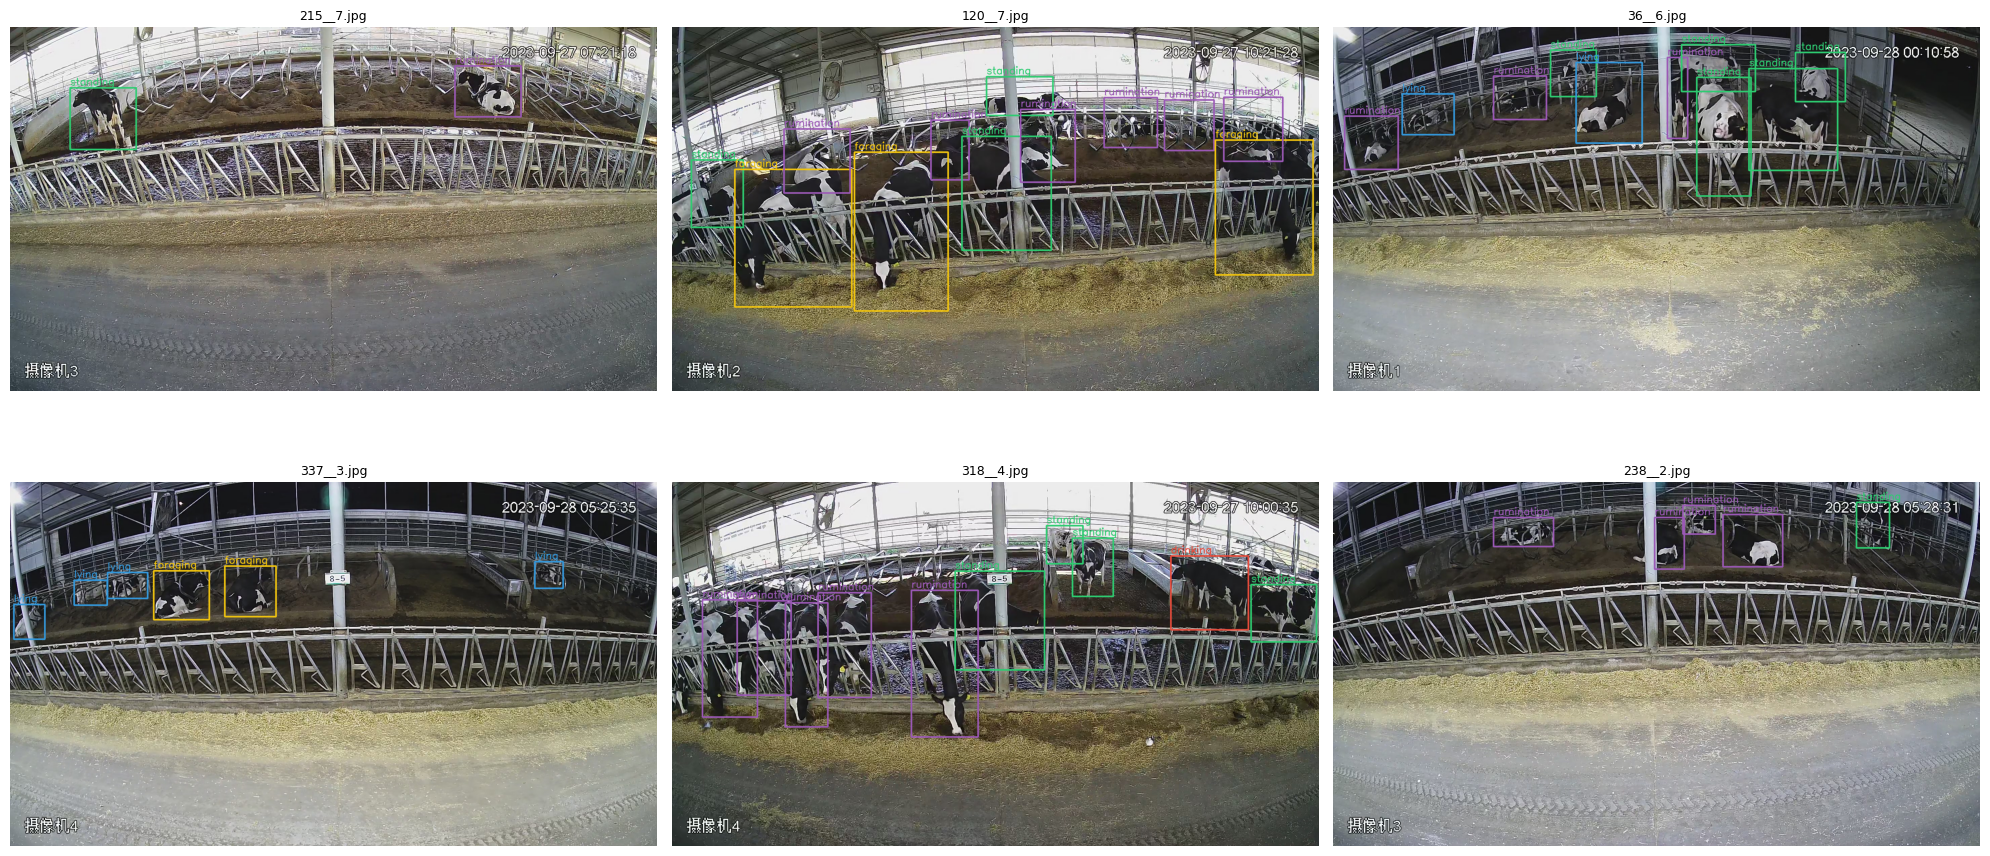

If boxes are NOT on the cows, the timestamp→image mapping or coordinates are wrong — stop here.


In [12]:
# ---- Visual sanity check: draw the converted YOLO labels back on images ----
COLORS = [(46, 204, 113), (52, 152, 219), (241, 196, 15), (231, 76, 60), (155, 89, 182)]
sample = random.sample(sorted((YOLO_DIR / "images" / "train").iterdir()), k=min(6, len(keys)))
fig, axes = plt.subplots(2, 3, figsize=(20, 10))
for ax, img_p in zip(axes.flat, sample):
    img = cv2.cvtColor(cv2.imread(str(img_p)), cv2.COLOR_BGR2RGB)
    H, W = img.shape[:2]
    for line in open(YOLO_DIR / "labels" / "train" / (img_p.stem + ".txt")):
        c, xc, yc, w, h = map(float, line.split())
        x1, y1 = int((xc - w / 2) * W), int((yc - h / 2) * H)
        x2, y2 = int((xc + w / 2) * W), int((yc + h / 2) * H)
        cv2.rectangle(img, (x1, y1), (x2, y2), COLORS[int(c)], 3)
        cv2.putText(img, CLASS_NAMES[int(c)], (x1, max(y1 - 8, 20)), cv2.FONT_HERSHEY_SIMPLEX, 1.0, COLORS[int(c)], 2)
    ax.imshow(img); ax.set_title(img_p.name, fontsize=9); ax.axis("off")
plt.tight_layout(); plt.show()
print("If boxes are NOT on the cows, the timestamp→image mapping or coordinates are wrong — stop here.")

## 10. Train YOLO11

In [13]:
import torch
from ultralytics import YOLO

DEVICE = 0 if torch.cuda.is_available() else "cpu"
print("Device:", torch.cuda.get_device_name(0) if DEVICE == 0 else "CPU (training will be very slow!)")

model = YOLO(MODEL_NAME)          # COCO-pretrained weights, fine-tuned on CBVD-5
model.train(
    data=str(DATA_YAML),
    epochs=EPOCHS,
    imgsz=IMGSZ,
    batch=BATCH,
    patience=PATIENCE,
    device=DEVICE,
    workers=WORKERS,
    project=str(PROJECT_DIR),
    name=RUN_NAME,
    exist_ok=True,
    seed=SEED,
    pretrained=True,
    optimizer="auto",
    cos_lr=True,
    close_mosaic=10,
    fliplr=0.5,
    flipud=0.0,          # cows are never upside down
    amp=True,
    plots=True,
    verbose=True,
)
RUN_DIR = Path(model.trainer.save_dir)
BEST_PT = RUN_DIR / "weights" / "best.pt"
print("Run dir :", RUN_DIR)
print("best.pt :", BEST_PT, BEST_PT.exists())

Creating new Ultralytics Settings v0.0.8 file ✅ 
View Ultralytics Settings with 'yolo settings' or at '/root/.config/Ultralytics/settings.json'
Update Settings with 'yolo settings key=value', i.e. 'yolo settings runs_dir=path/to/dir'. For help see https://docs.ultralytics.com/usage/settings.
Device: Tesla T4
Ultralytics 8.4.174 🚀 Python-3.13.15 torch-2.11.0+cu128 CUDA:0 (Tesla T4, 14912MiB)
engine/trainer: agnostic_nms=False, amp=True, angle=1.0, augment=False, auto_augment=randaugment, batch=16, bgr=0.0, box=7.5, cache=False, cfg=None, channels_last=None, classes=None, close_mosaic=10, cls=0.5, cls_pw=0.0, cls_remap=True, compile=False, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=True, cutmix=0.0, data=/kaggle/working/cbvd5_yolo/data.yaml, degrees=0.0, deterministic=True, device=0, dfl=1.5, dgrad=0.5, dis=6.0, distill_model=None, dlam=1.0, dlog=1.0, dnn=False, dropout=0.0, dynamic=False, embed=None, epochs=100, erasing=0.4, exist_ok=True, fliplr=0.5, flipud=0.0, format=tor

results.png


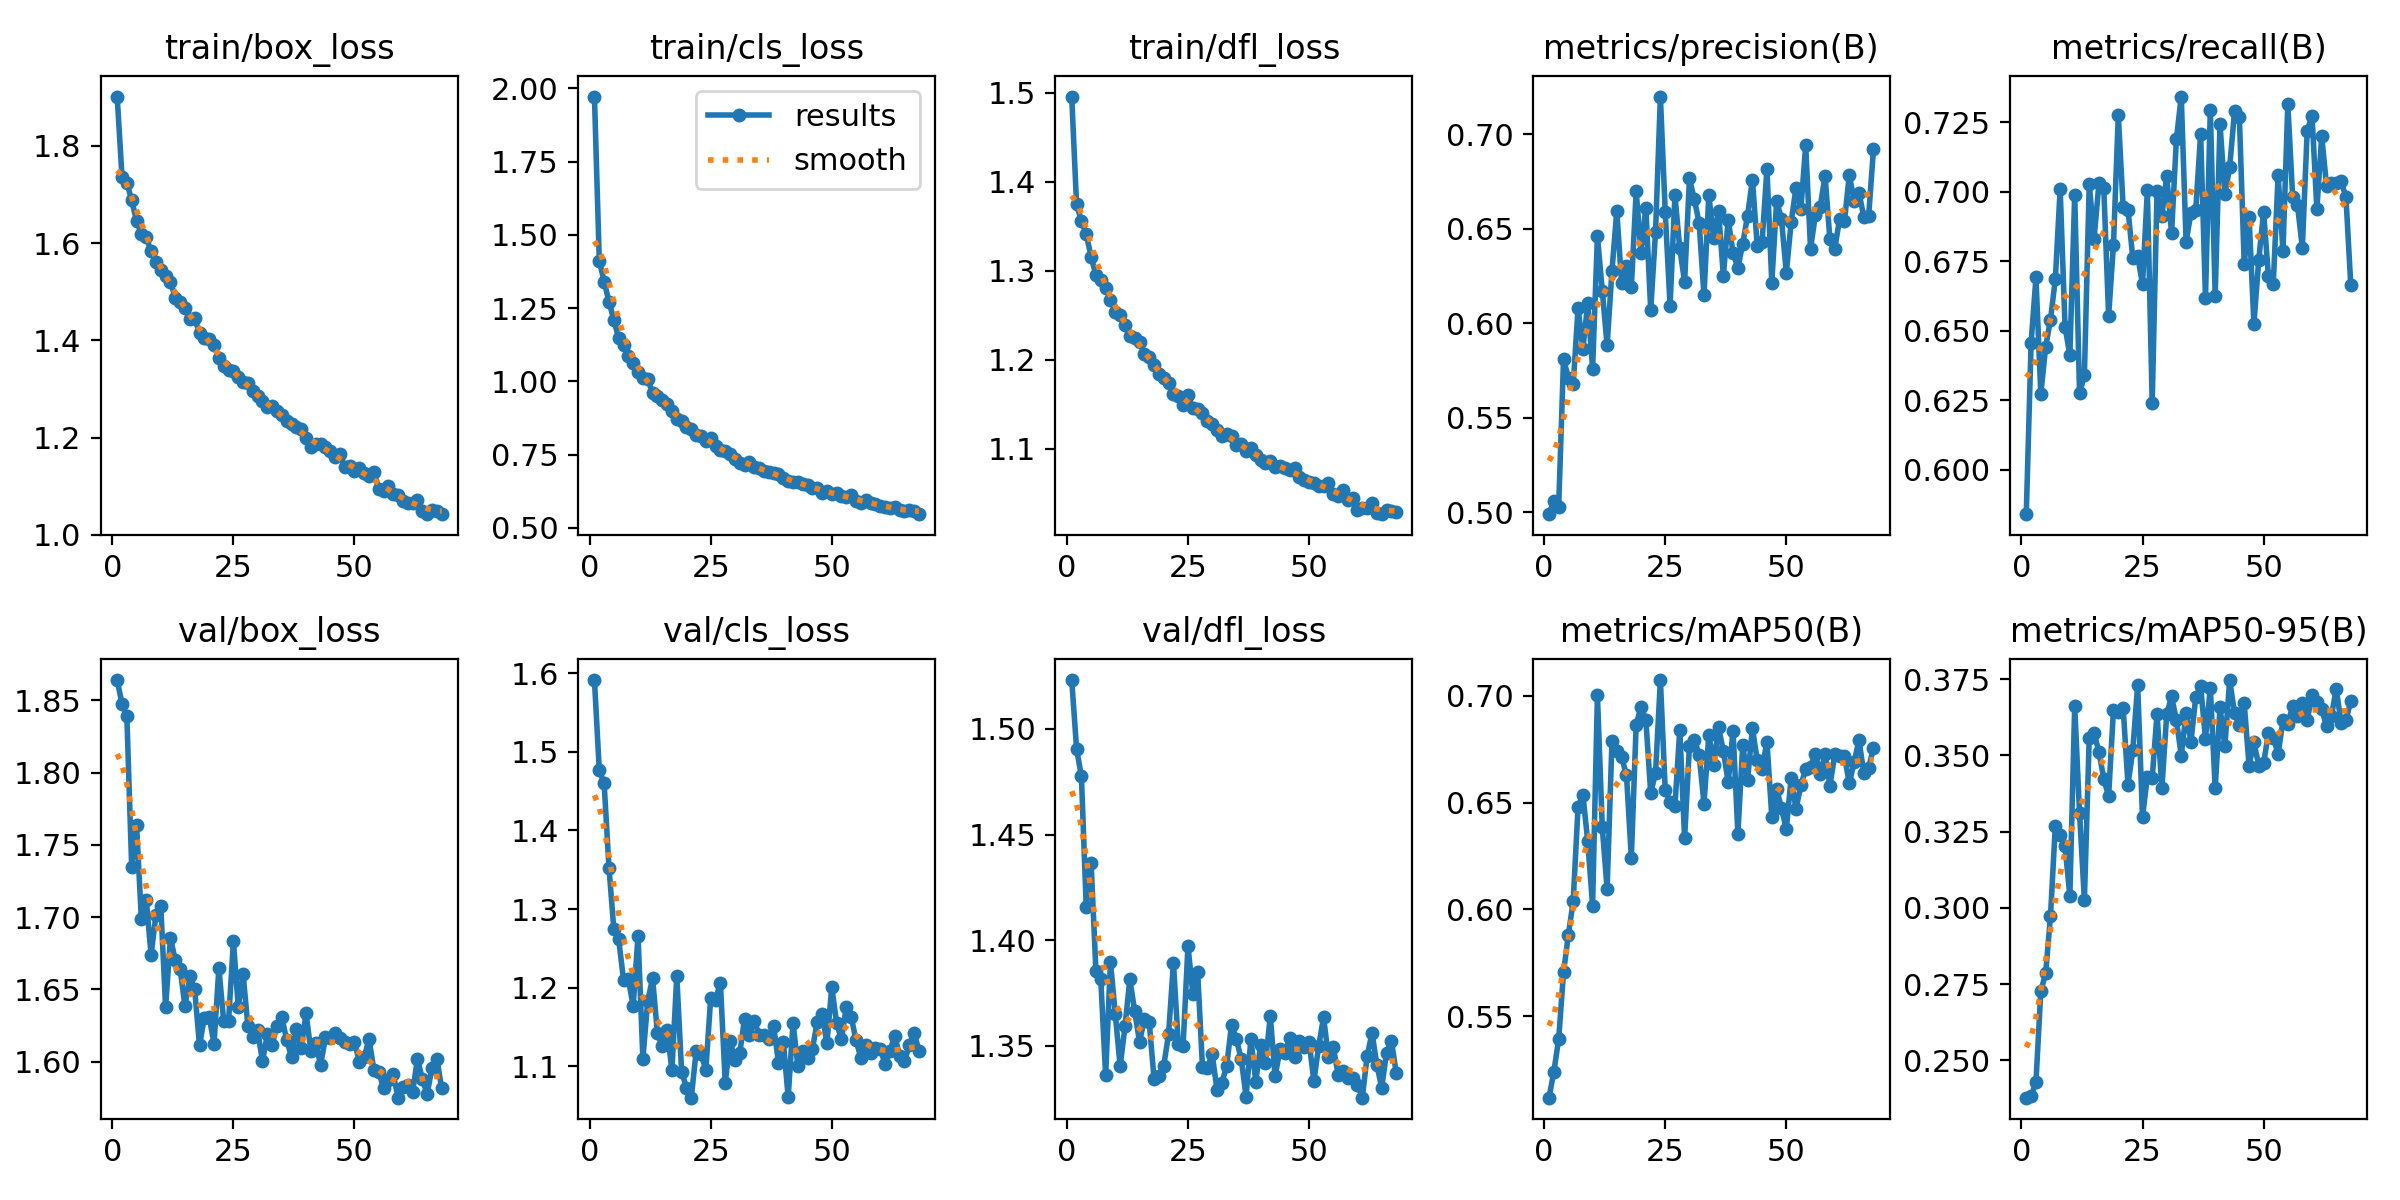

confusion_matrix.png


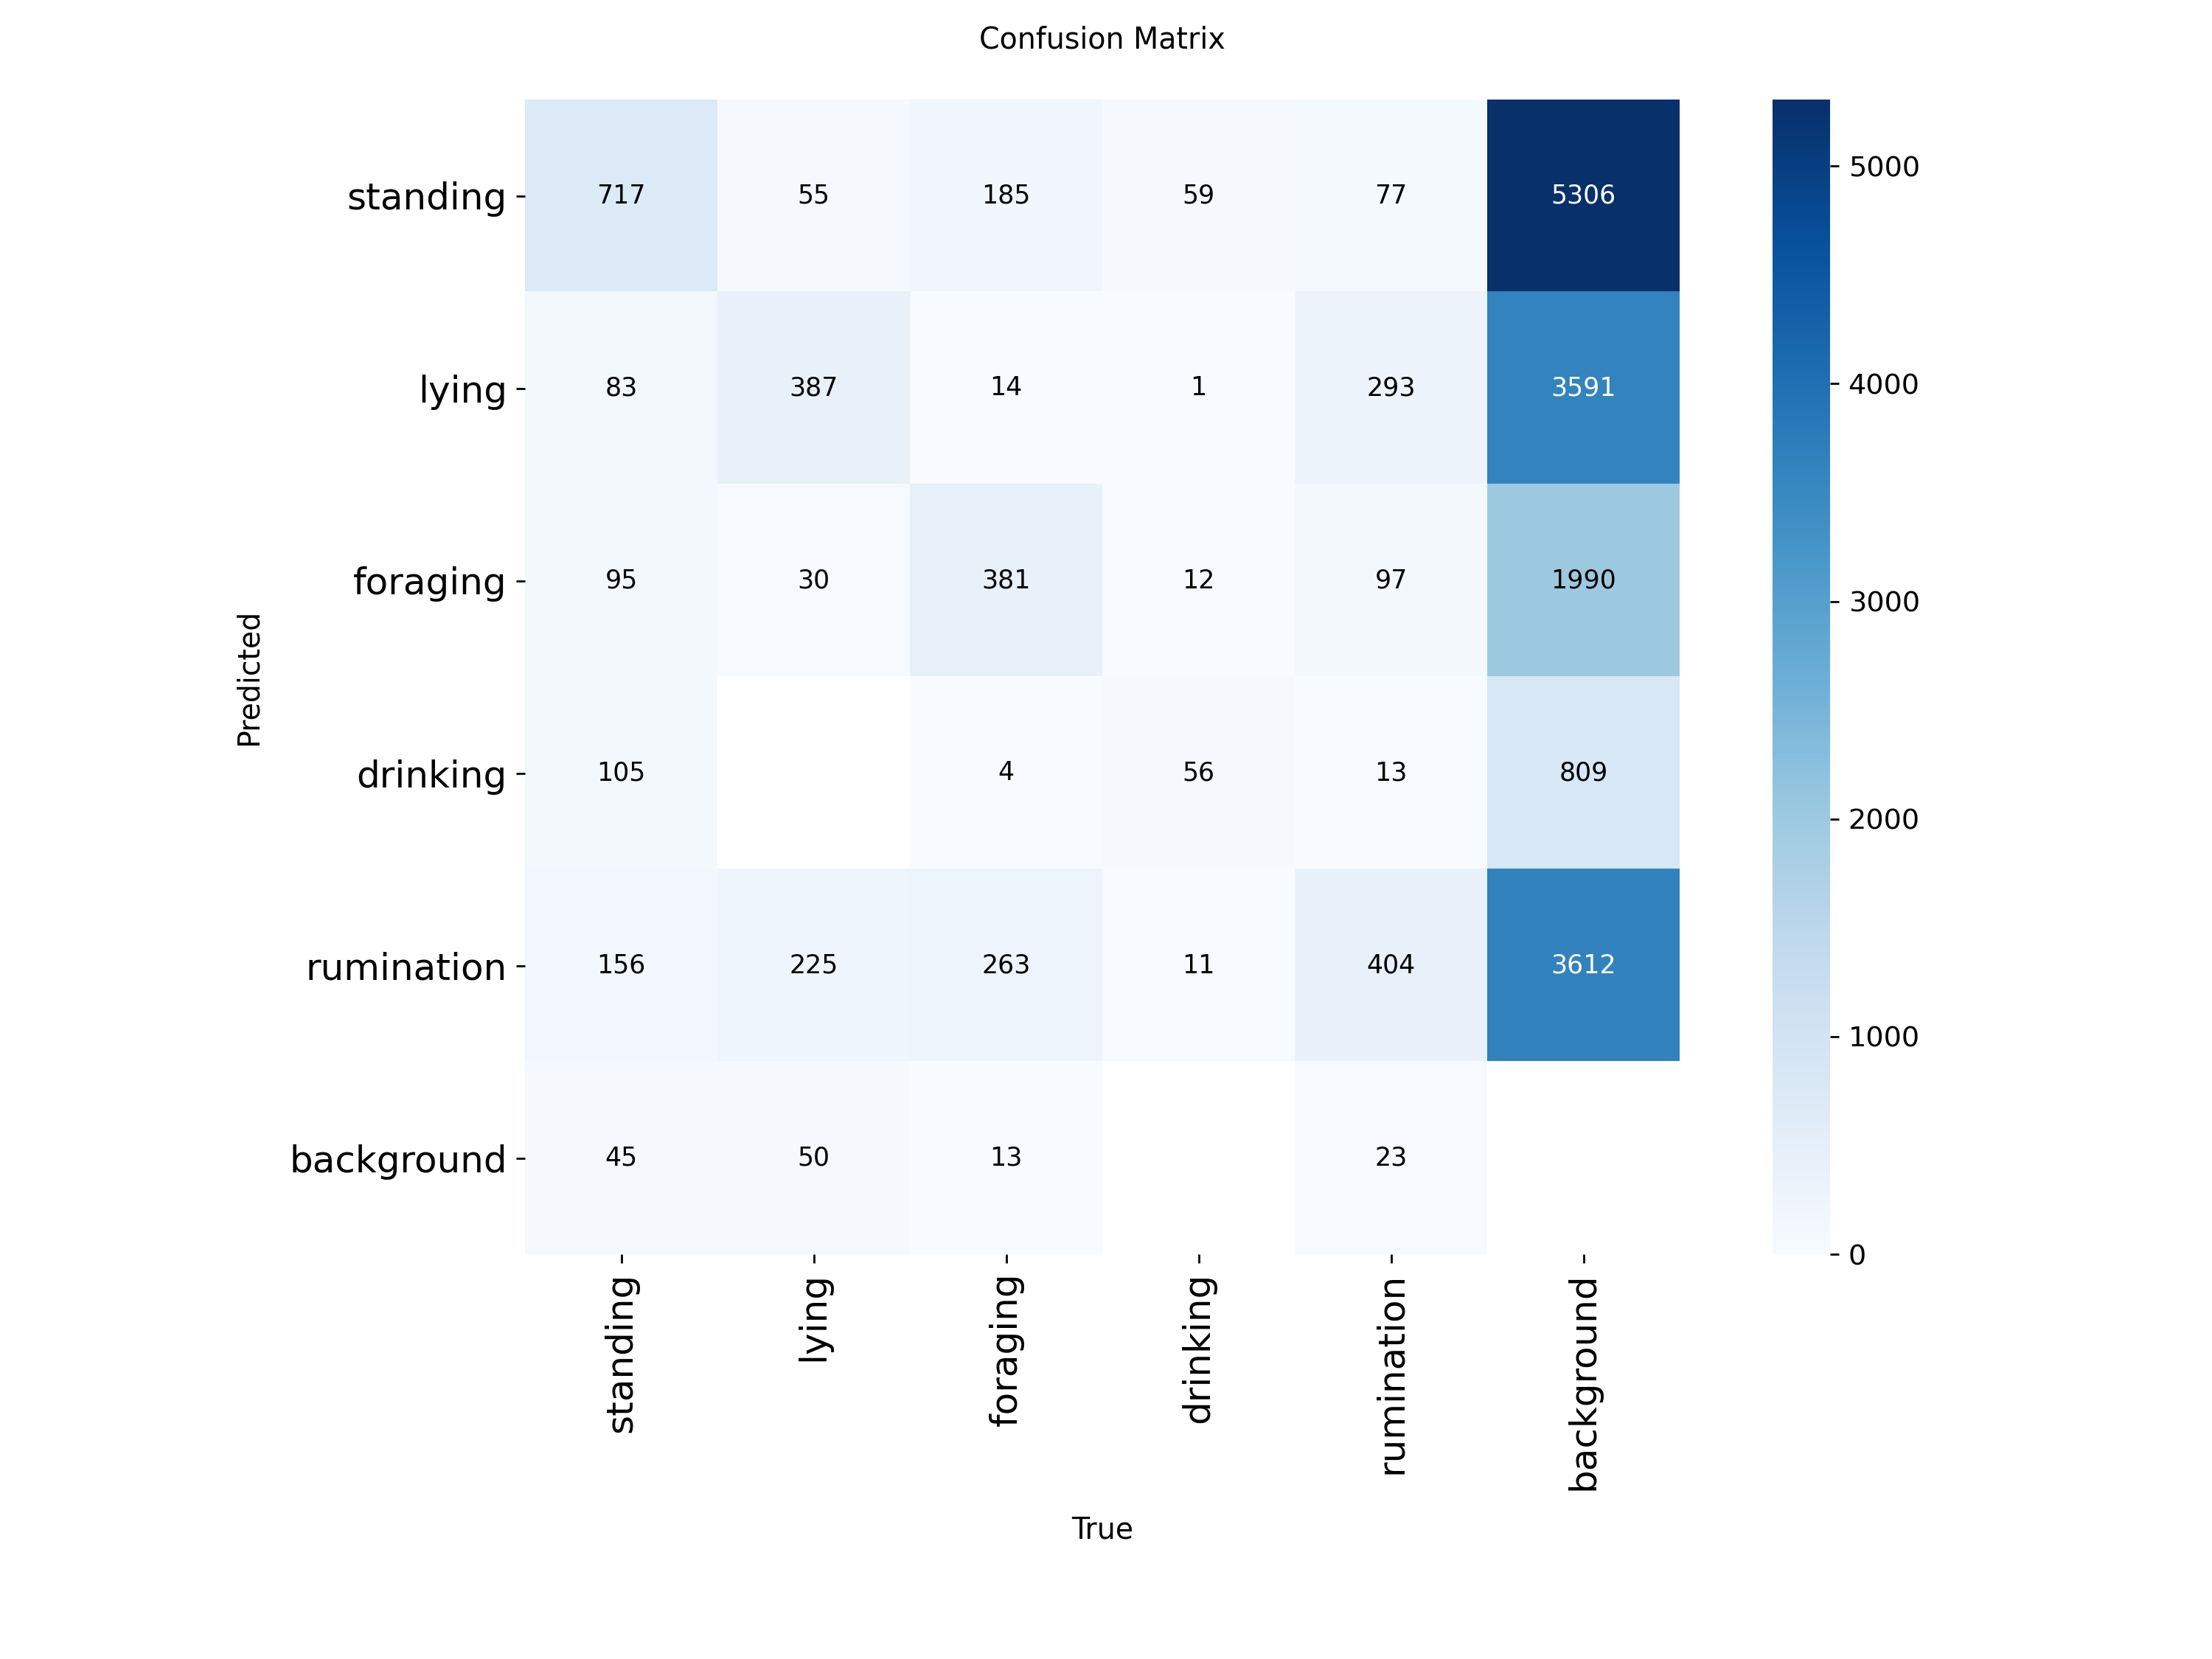

confusion_matrix_normalized.png


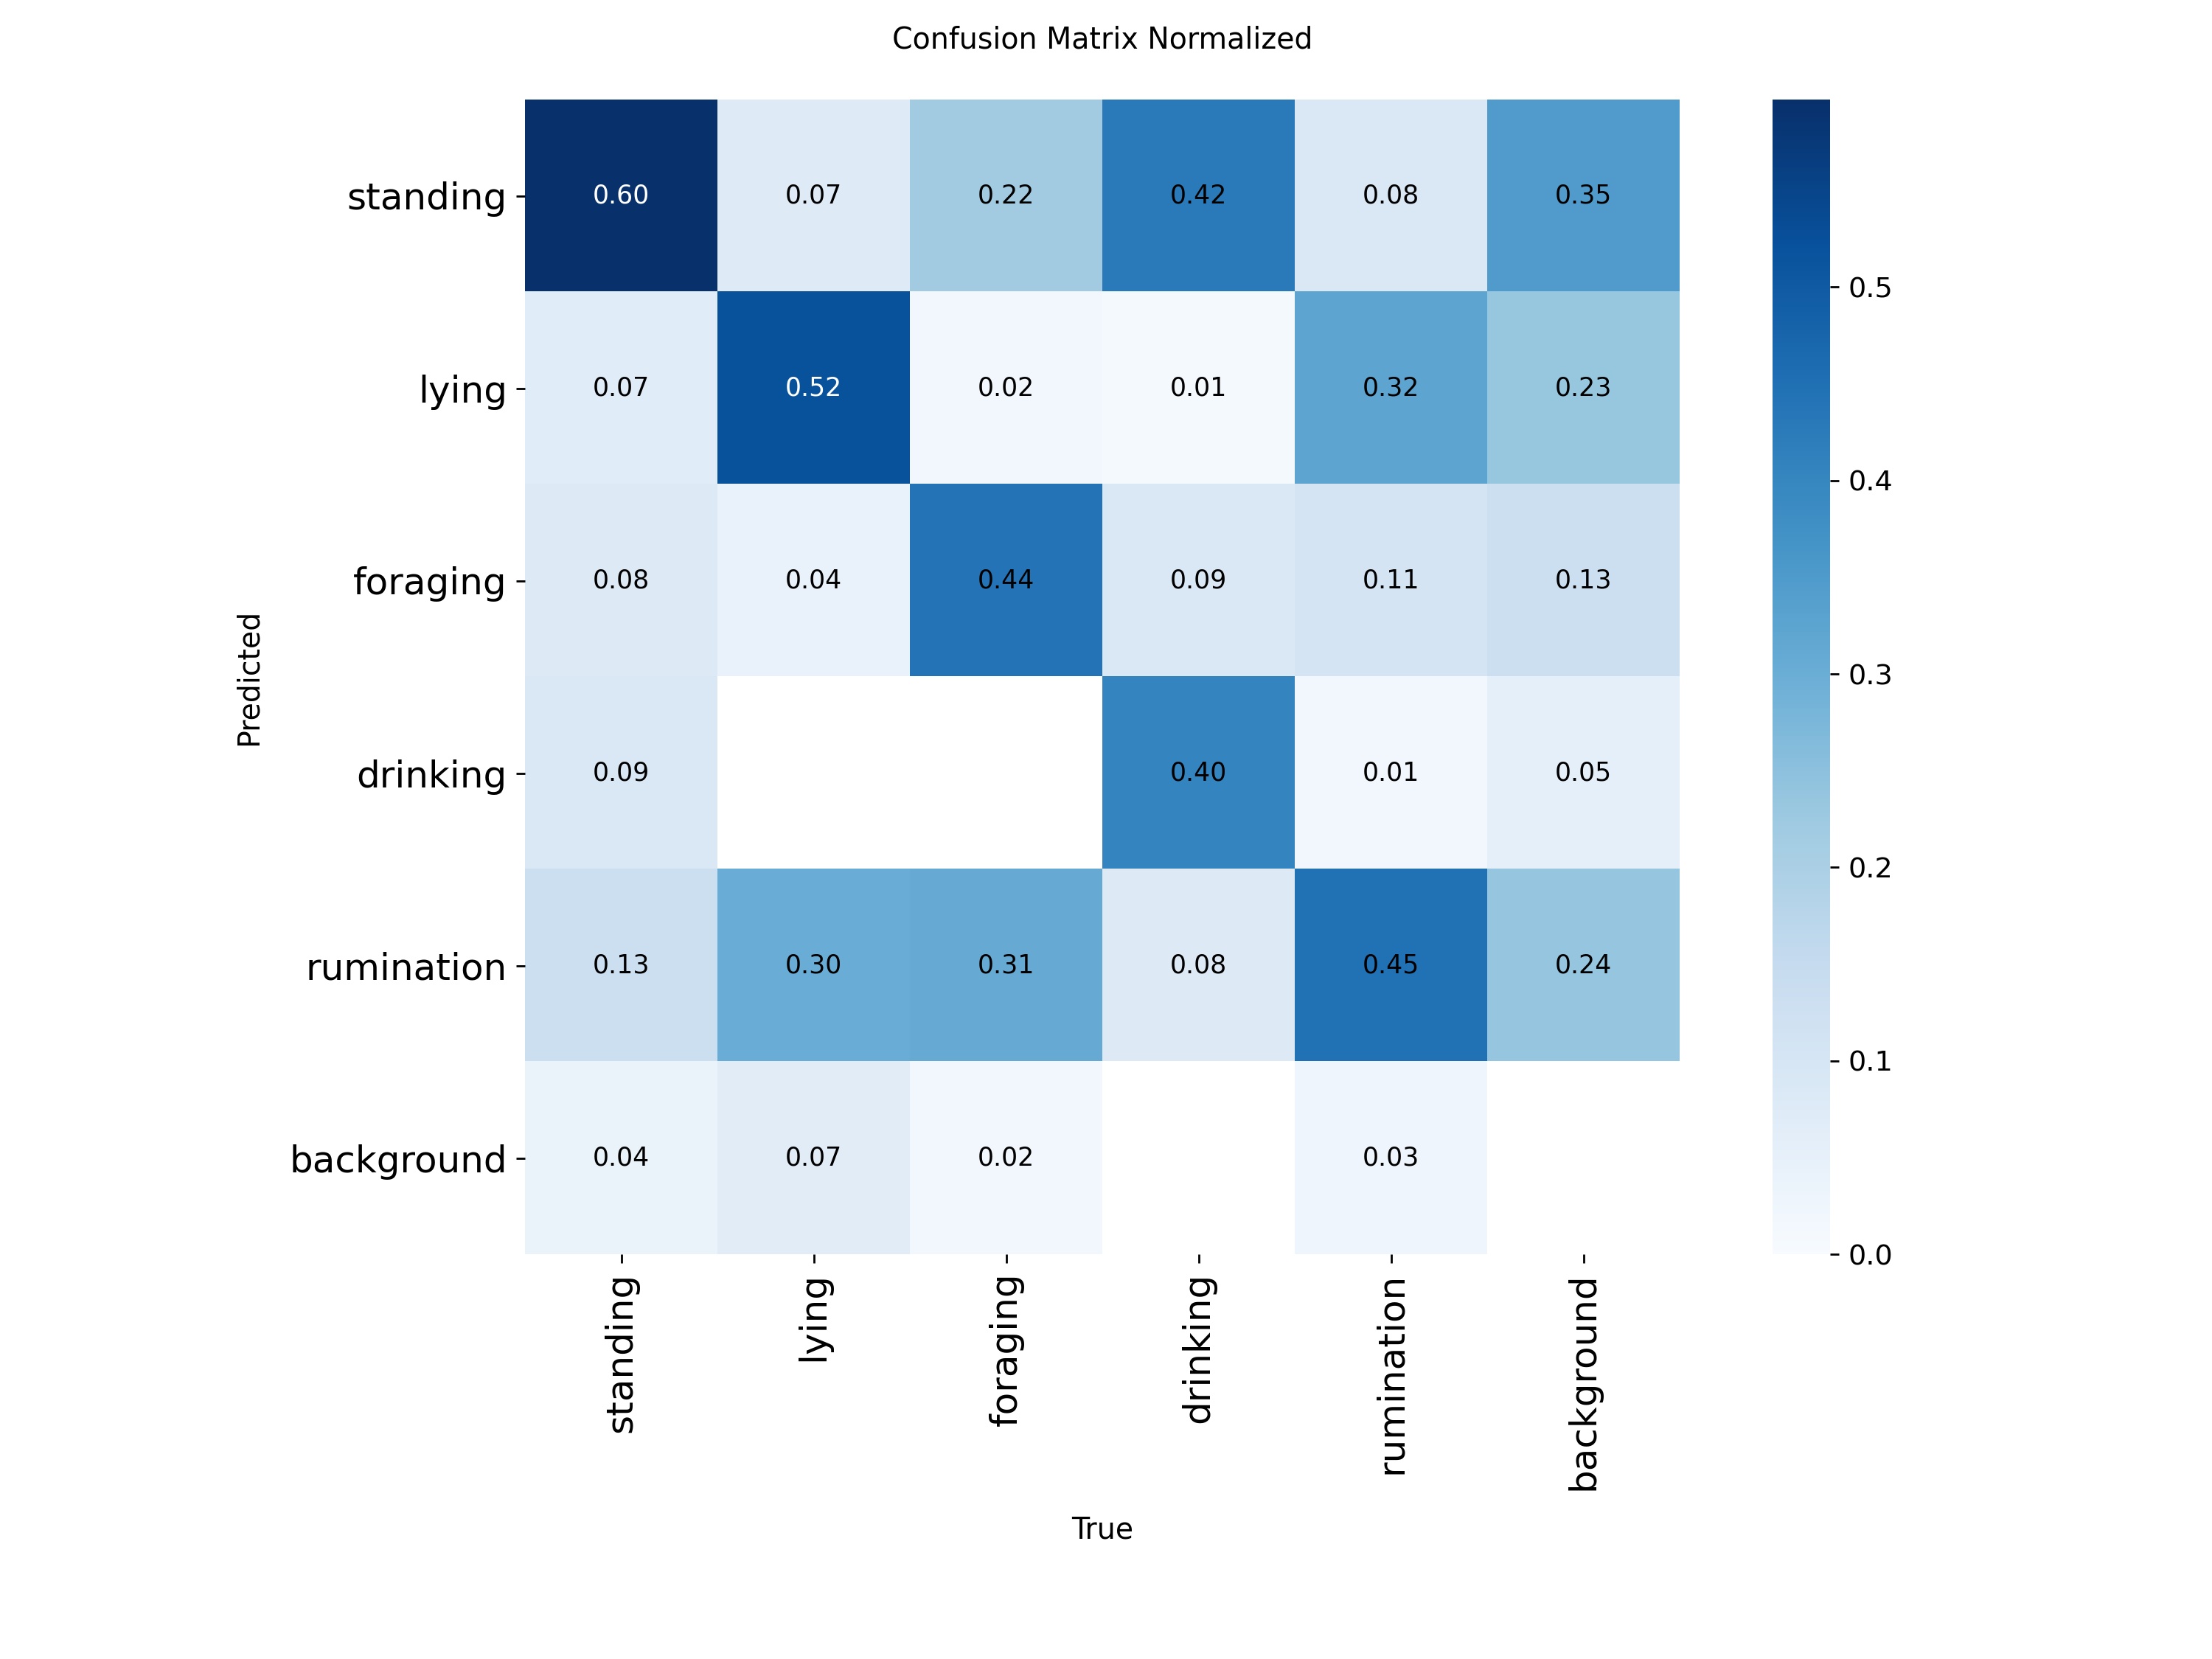

Files in run dir: ['BoxF1_curve.png', 'BoxPR_curve.png', 'BoxP_curve.png', 'BoxR_curve.png', 'args.yaml', 'confusion_matrix.png', 'confusion_matrix_normalized.png', 'labels.jpg', 'results.csv', 'results.png', 'train_batch0.jpg', 'train_batch1.jpg', 'train_batch2.jpg', 'val_batch0_labels.jpg', 'val_batch0_pred.jpg', 'val_batch1_labels.jpg', 'val_batch1_pred.jpg', 'val_batch2_labels.jpg', 'val_batch2_pred.jpg', 'weights']


In [14]:
# ---- Training curves + confusion matrix of the final validation ----
for name in ["results.png", "confusion_matrix.png", "confusion_matrix_normalized.png"]:
    p = RUN_DIR / name
    if p.exists():
        print(name); display(IPyImage(filename=str(p), width=1000))
print("Files in run dir:", sorted(os.listdir(RUN_DIR)))

## 11. Evaluate `best.pt` on validation and test sets

In [15]:
best = YOLO(str(BEST_PT))

def instance_counts(split):
    cnt = Counter()
    for f in (YOLO_DIR / "labels" / split).glob("*.txt"):
        for line in open(f):
            cnt[int(line.split()[0])] += 1
    return cnt

def evaluate(split):
    m = best.val(data=str(DATA_YAML), split=split, imgsz=IMGSZ, batch=BATCH if BATCH > 0 else 16,
                 device=DEVICE, project=str(PROJECT_DIR), name=f"{RUN_NAME}_{split}", exist_ok=True,
                 plots=True, verbose=False)
    cnt = instance_counts(split)
    rows = []
    for i, c in enumerate(m.box.ap_class_index):
        p, r, ap50, ap = m.box.class_result(i)
        rows.append({"class": CLASS_NAMES[int(c)], "instances": cnt.get(int(c), 0),
                     "precision": p, "recall": r, "f1": 2 * p * r / (p + r + 1e-16),
                     "mAP50": ap50, "mAP50-95": ap})
    per_class = pd.DataFrame(rows).set_index("class").reindex(CLASS_NAMES)
    mp, mr = m.box.mp, m.box.mr
    overall = {"split": split, "precision": mp, "recall": mr, "f1": 2 * mp * mr / (mp + mr + 1e-16),
               "mAP50": m.box.map50, "mAP50-95": m.box.map}
    return m, overall, per_class

results = {}
for split in ["val", "test"]:
    m, overall, per_class = evaluate(split)
    results[split] = (m, overall, per_class)
    print(f"\n==================== {split.upper()} ====================")
    print({k: (round(v, 4) if isinstance(v, float) else v) for k, v in overall.items()})
    display(per_class.round(4))

Ultralytics 8.4.174 🚀 Python-3.13.15 torch-2.11.0+cu128 CUDA:0 (Tesla T4, 14912MiB)
YOLO11s summary (fused): 100 layers, 9,414,735 parameters, 0 gradients, 21.4 GFLOPs
val: Fast image access ✅ (ping: 0.0±0.0 ms, read: 4659.0±962.5 MB/s, size: 748.3 KB)
val: Scanning /kaggle/working/cbvd5_yolo/labels/val.cache... 480 images, 0 backgrounds, 0 corrupt: 100% ━━━━━━━━━━━━ 480/480 167.8Mit/s 0.0s
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 30/30 4.4it/s 6.8s
                   all        480       3854      0.676      0.709      0.685      0.375
Speed: 0.9ms preprocess, 5.3ms inference, 0.0ms loss, 2.8ms postprocess per image
Results saved to /kaggle/working/runs/detect/cattle_behavior_val

==================== VAL ====================
{'split': 'val', 'precision': np.float64(0.6762), 'recall': np.float64(0.7091), 'f1': np.float64(0.6923), 'mAP50': np.float64(0.685), 'mAP50-95': np.float64(0.3749)}


,instances,precision,recall,f1,mAP50,mAP50-95
class,,,,,,
standing,1201,0.6564,0.7173,0.6855,0.6772,0.3279
lying,747,0.6186,0.6537,0.6357,0.5973,0.2828
foraging,860,0.8436,0.7465,0.7921,0.8450,0.5425
drinking,139,0.5702,0.7050,0.6305,0.6391,0.3519
rumination,907,0.6923,0.7233,0.7074,0.6663,0.3696


Ultralytics 8.4.174 🚀 Python-3.13.15 torch-2.11.0+cu128 CUDA:0 (Tesla T4, 14912MiB)
YOLO11s summary (fused): 100 layers, 9,414,735 parameters, 0 gradients, 21.4 GFLOPs
val: Fast image access ✅ (ping: 0.0±0.0 ms, read: 5097.4±1157.2 MB/s, size: 696.6 KB)
val: Scanning /kaggle/working/cbvd5_yolo/labels/test... 441 images, 0 backgrounds, 0 corrupt: 100% ━━━━━━━━━━━━ 441/441 1.1Kit/s 0.4s
val: New cache created: /kaggle/working/cbvd5_yolo/labels/test.cache
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 28/28 4.4it/s 6.4s
                   all        441       3064      0.637      0.645      0.635      0.334
Speed: 0.9ms preprocess, 5.4ms inference, 0.0ms loss, 3.1ms postprocess per image
Results saved to /kaggle/working/runs/detect/cattle_behavior_test

==================== TEST ====================
{'split': 'test', 'precision': np.float64(0.6374), 'recall': np.float64(0.6449), 'f1': np.float64(0.6411), 'mAP50': np.float64(0.63

,instances,precision,recall,f1,mAP50,mAP50-95
class,,,,,,
standing,946,0.6988,0.6829,0.6907,0.6721,0.3134
lying,675,0.5682,0.4093,0.4758,0.4736,0.2153
foraging,612,0.7770,0.8987,0.8334,0.8554,0.5644
drinking,71,0.5786,0.5915,0.5850,0.6054,0.2766
rumination,760,0.5645,0.6421,0.6008,0.5661,0.3004


,pred_standing,pred_lying,pred_foraging,pred_drinking,pred_rumination,pred_background
true_standing,539,46,82,70,159,50
true_lying,63,235,35,1,308,33
true_foraging,140,8,323,6,126,9
true_drinking,25,0,1,39,5,1
true_rumination,115,267,80,4,280,14
true_background,5632,2904,1423,569,3557,0


confusion_matrix_normalized.png


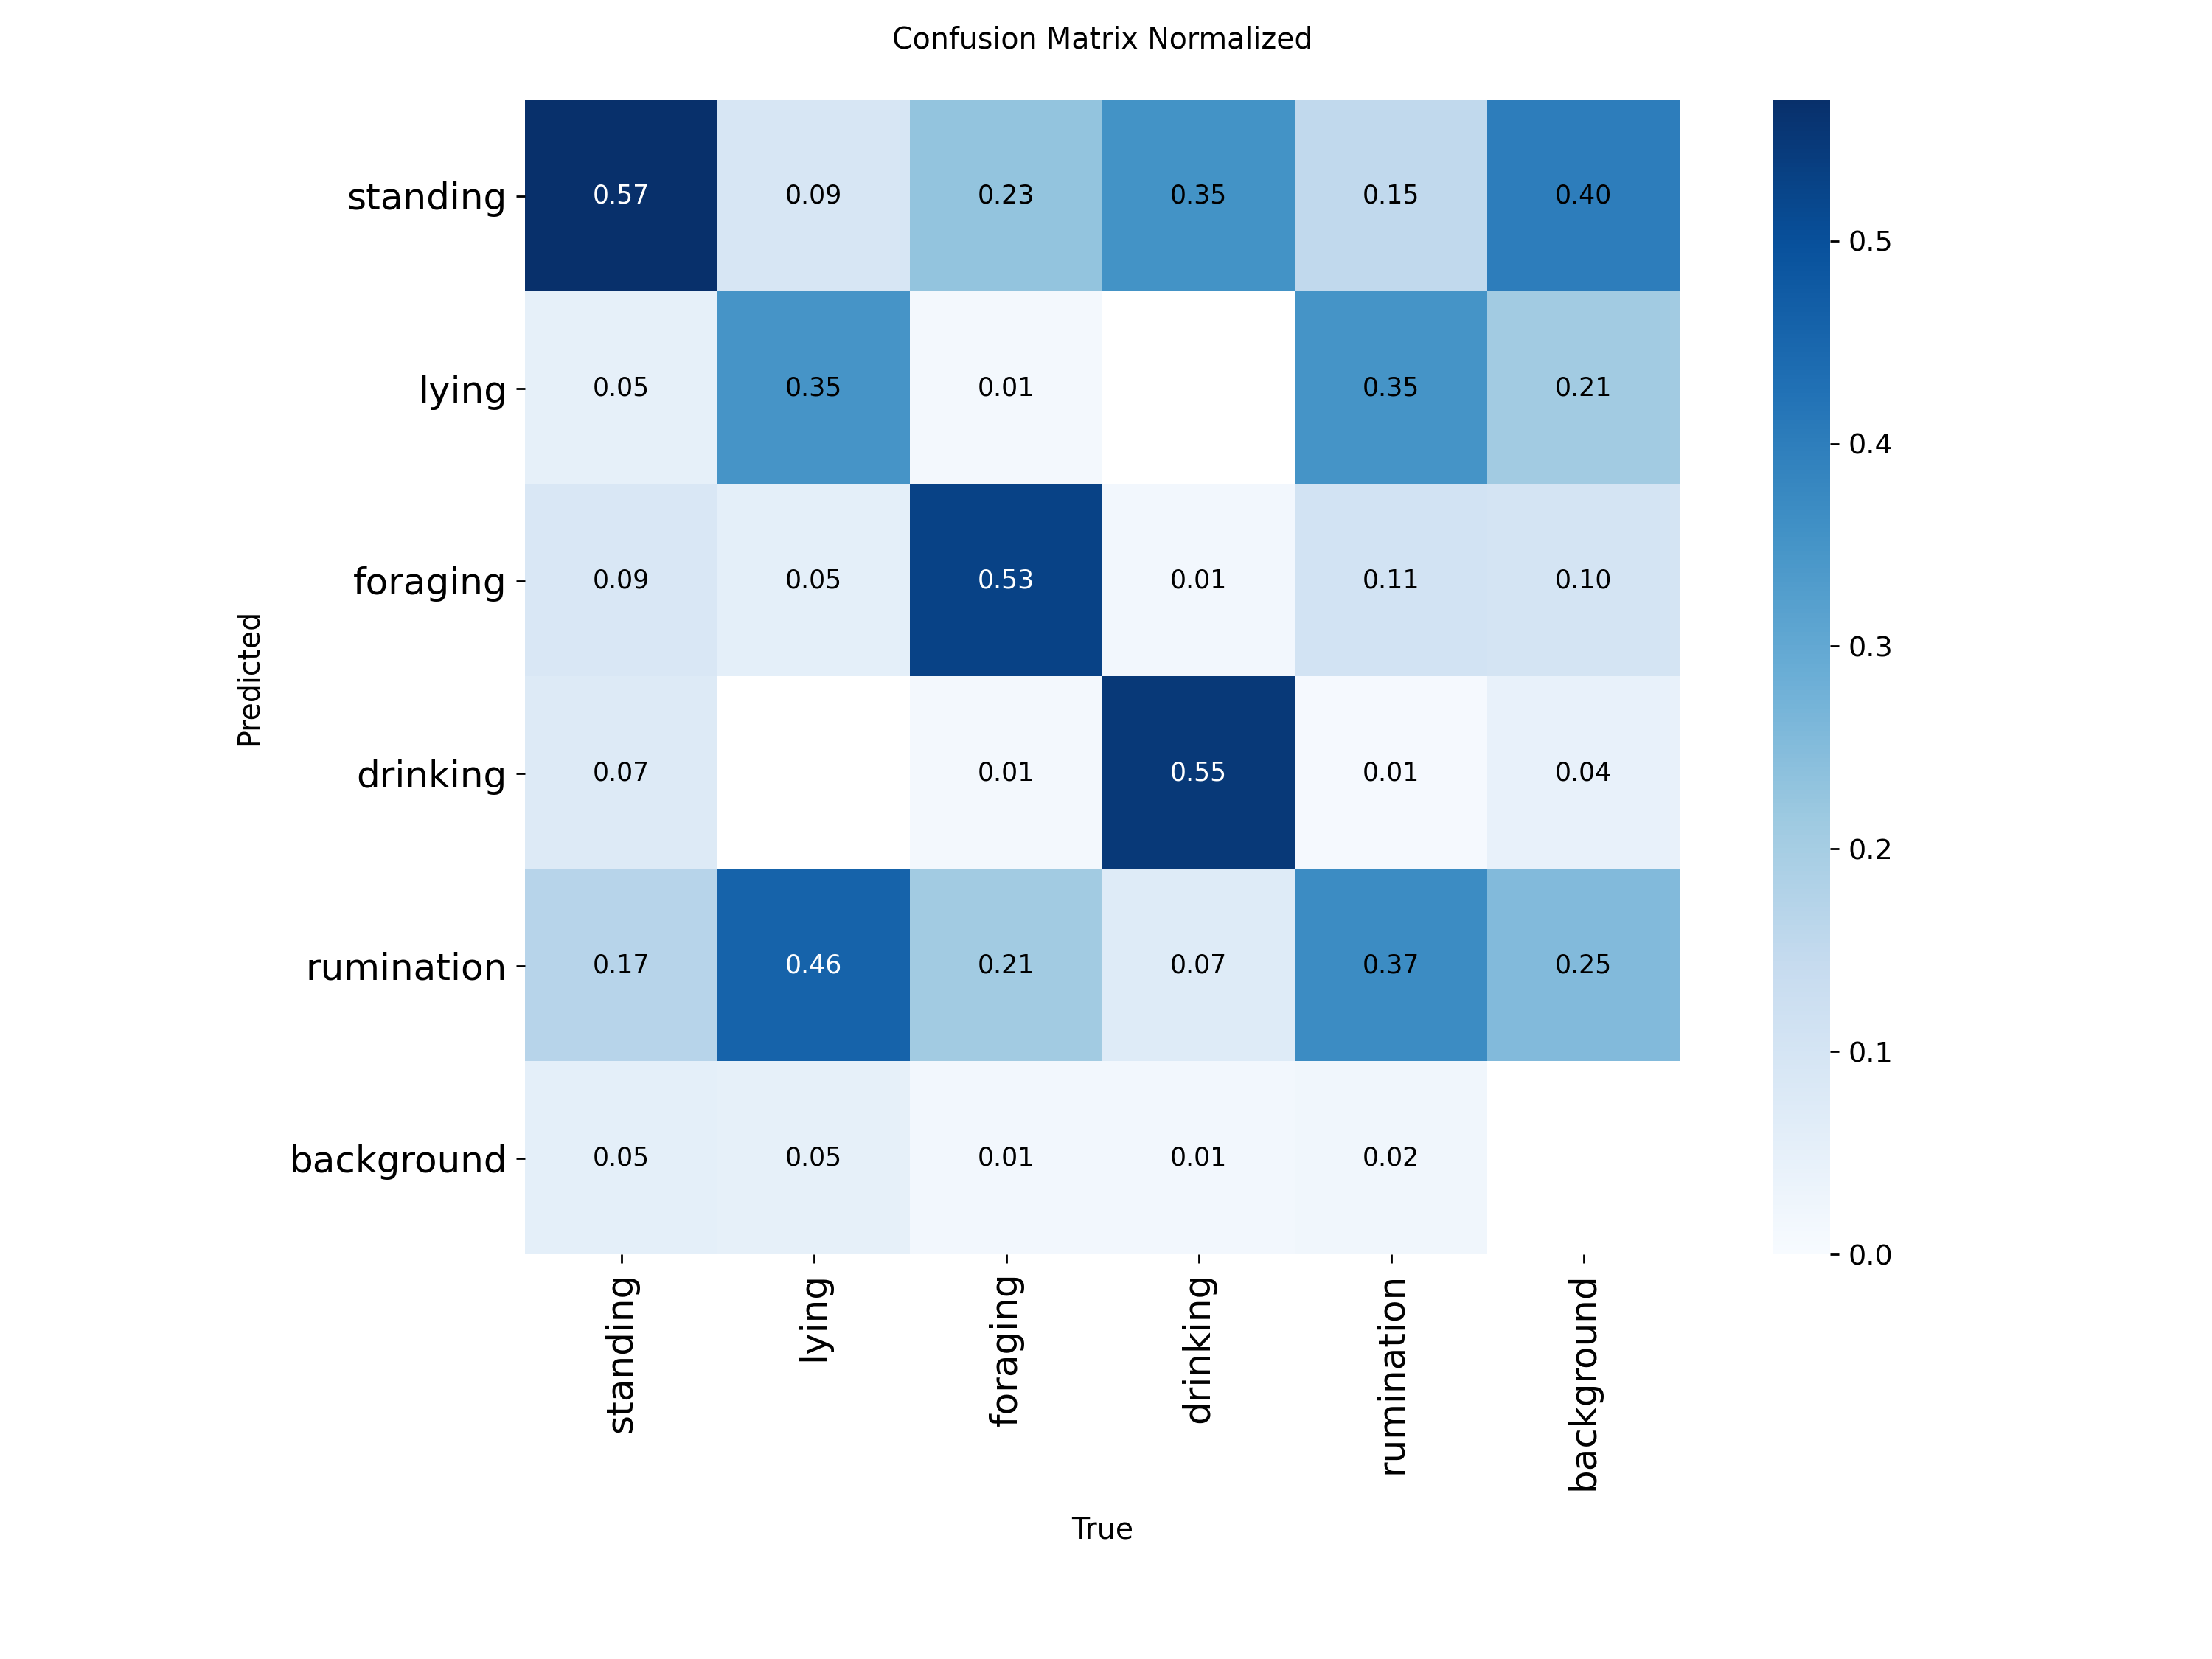

confusion_matrix.png


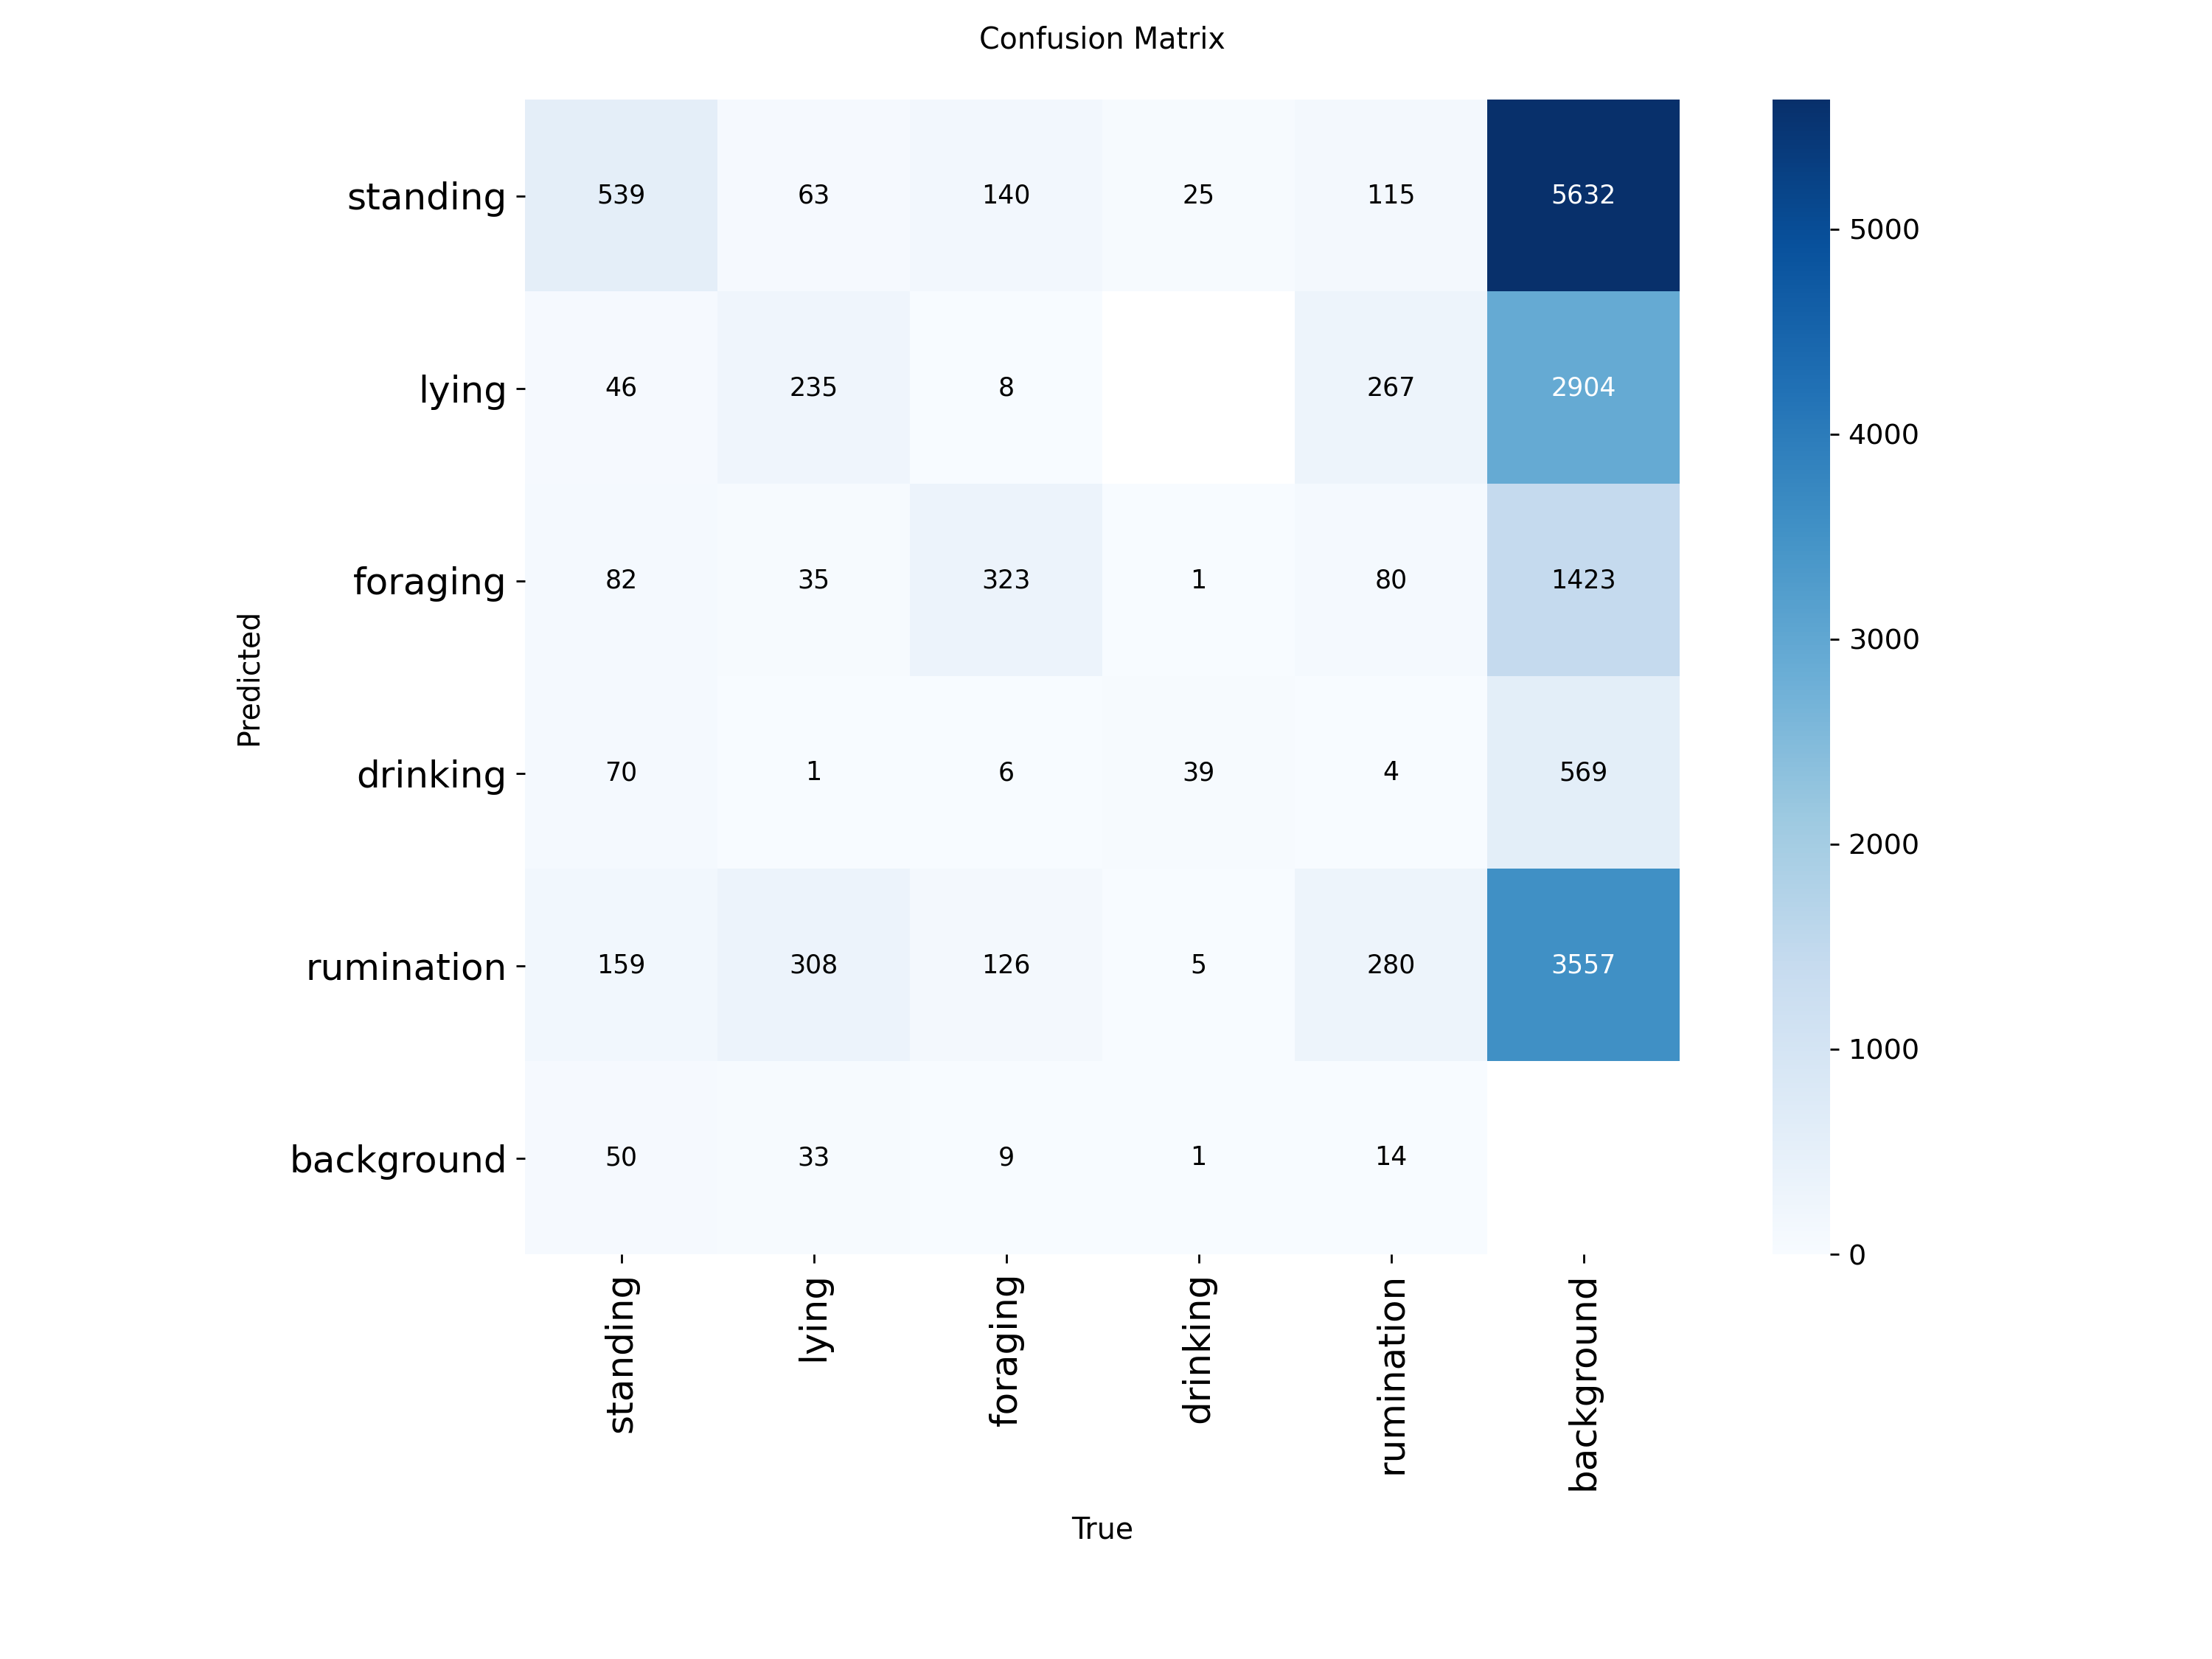

BoxPR_curve.png


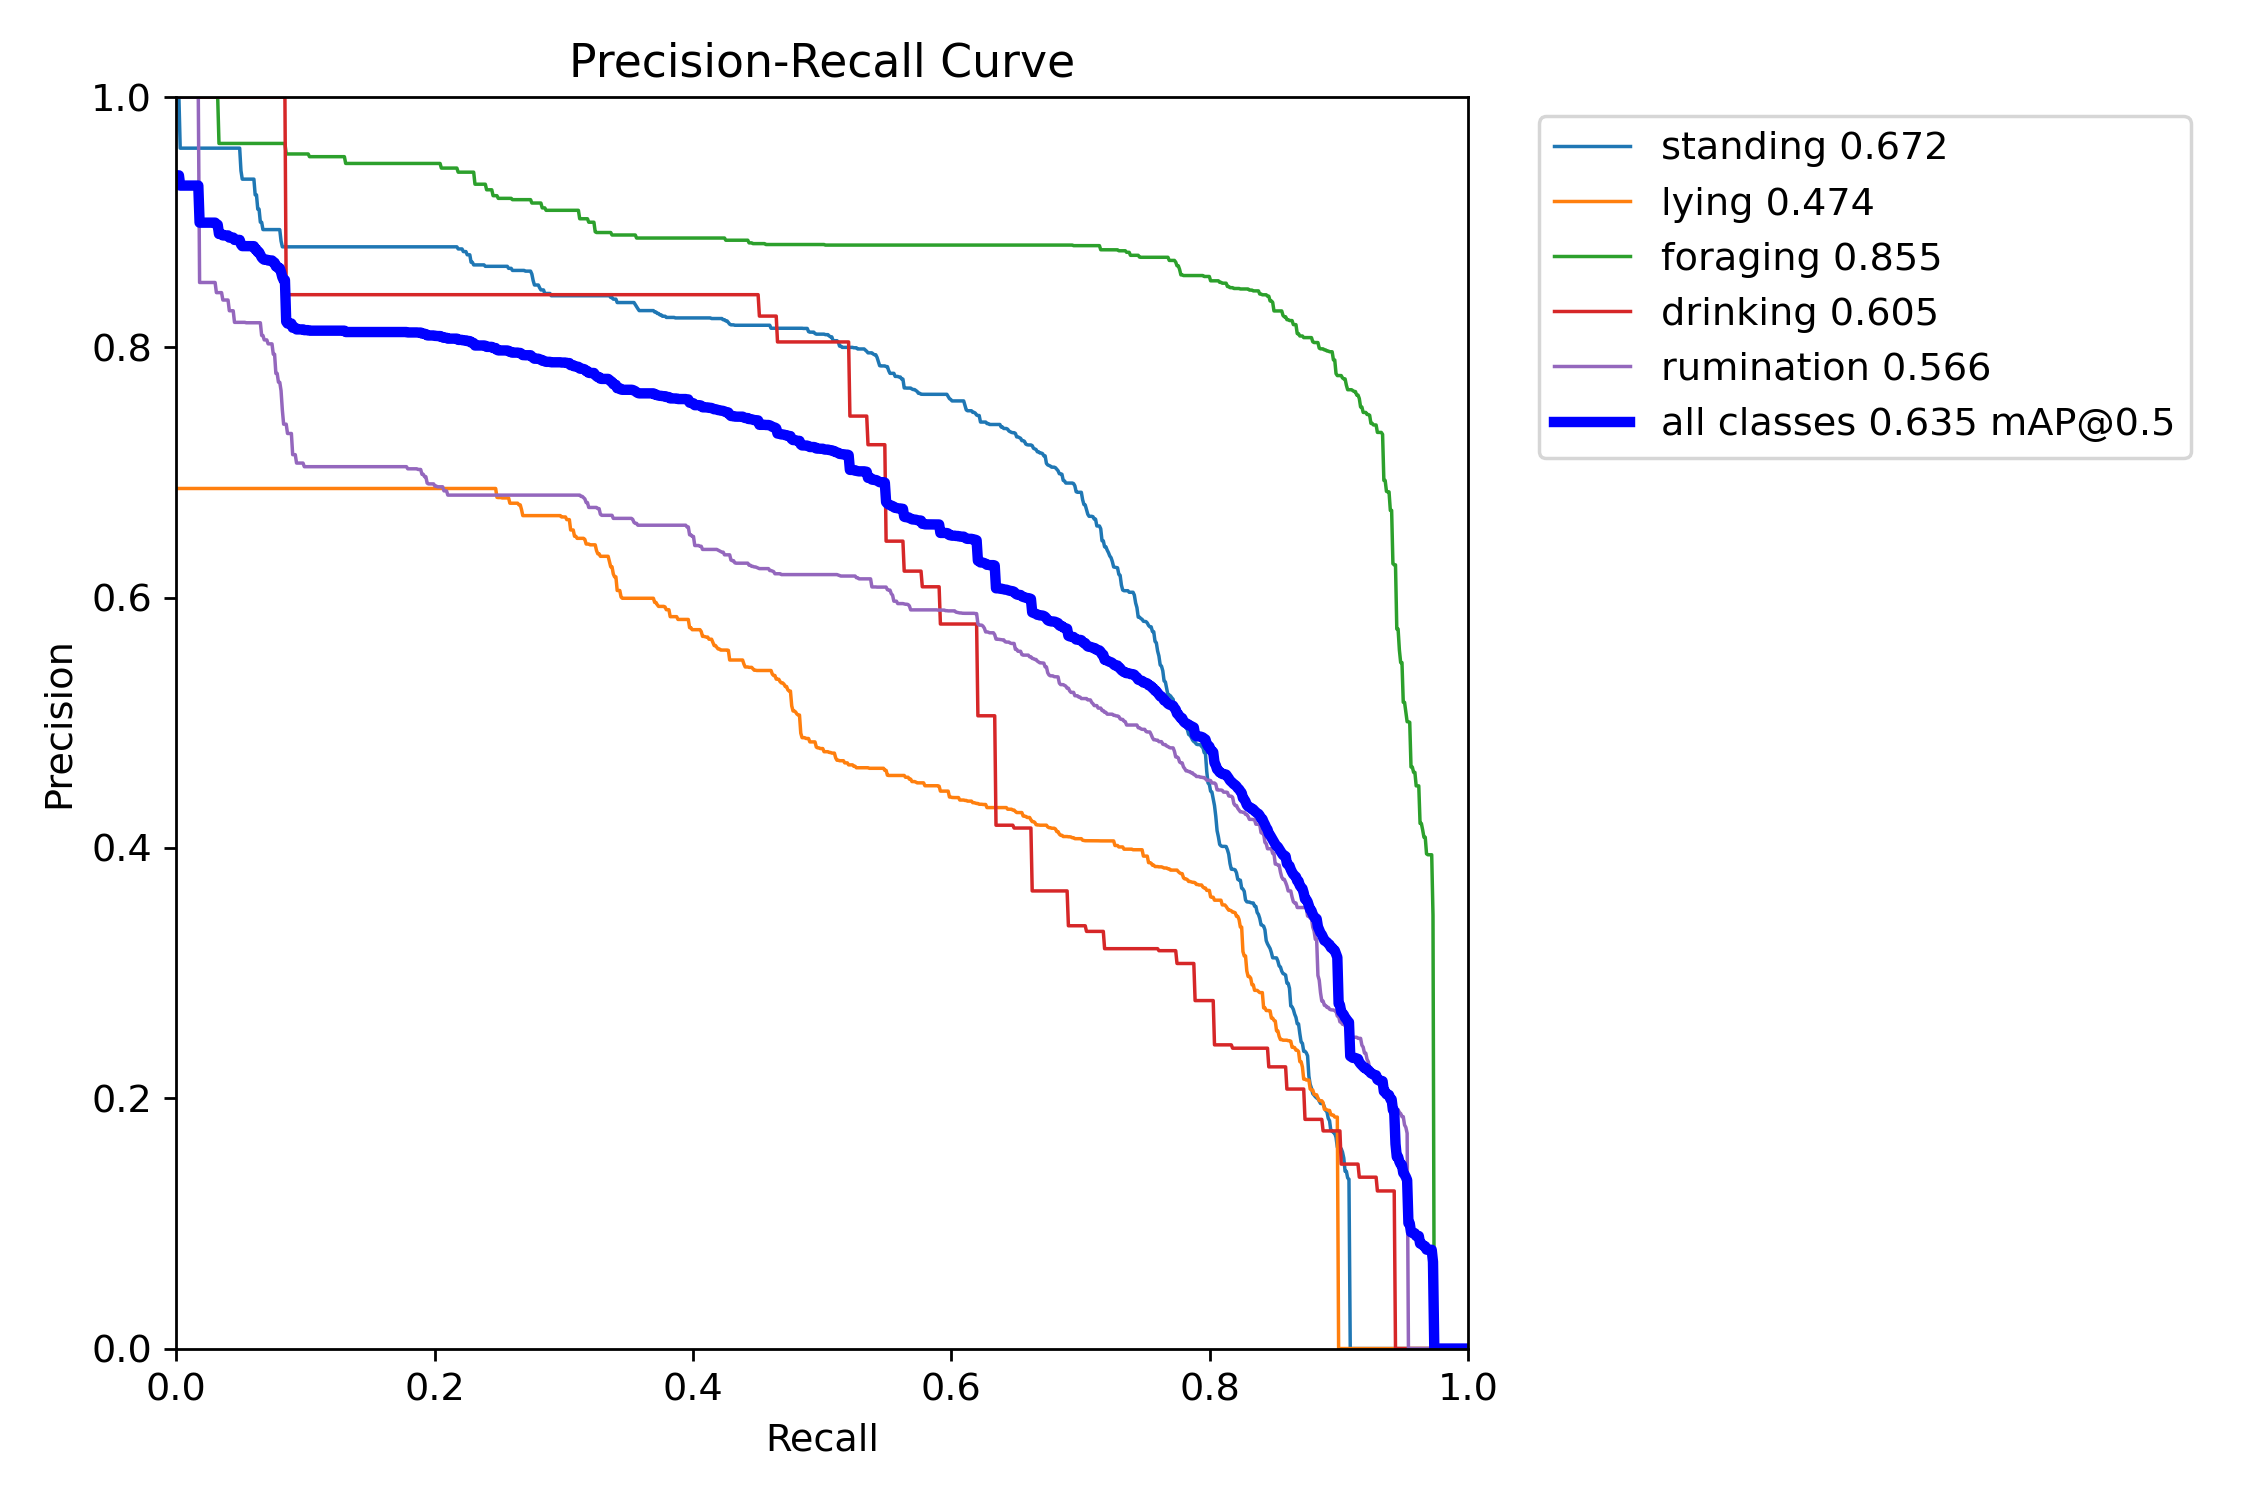

In [16]:
# ---- Confusion matrix on the TEST set (rows = true class, cols = predicted) ----
m_test = results["test"][0]
try:
    cm = m_test.confusion_matrix.matrix.T          # ultralytics stores [pred, true]
    labels = CLASS_NAMES + ["background"]
    display(pd.DataFrame(cm.astype(int), index=[f"true_{l}" for l in labels],
                         columns=[f"pred_{l}" for l in labels]))
except Exception as e:
    print("Could not read confusion matrix array:", e)

for name in ["confusion_matrix_normalized.png", "confusion_matrix.png", "PR_curve.png", "BoxPR_curve.png"]:
    p = Path(getattr(m_test, "save_dir", None) or PROJECT_DIR / f"{RUN_NAME}_test") / name
    if p.exists():
        print(name); display(IPyImage(filename=str(p), width=900))

## 12. Save final model, metrics and a downloadable archive

In [17]:
shutil.copy2(BEST_PT, WORK_DIR / "best.pt")

summary = {
    "model": MODEL_NAME, "epochs_requested": EPOCHS, "imgsz": IMGSZ,
    "classes": CLASS_NAMES, "label_priority": LABEL_PRIORITY,
    "action_id_map": {int(k): v for k, v in ACTION_ID_TO_CLASS.items()},
    "split_table": split_table.reset_index().to_dict(orient="records"),
    "val":  {k: float(v) if not isinstance(v, str) else v for k, v in results["val"][1].items()},
    "test": {k: float(v) if not isinstance(v, str) else v for k, v in results["test"][1].items()},
    "test_per_class": results["test"][2].reset_index().to_dict(orient="records"),
}
with open(WORK_DIR / "metrics_summary.json", "w") as f:
    json.dump(summary, f, indent=2, default=float)
results["val"][2].to_csv(WORK_DIR / "per_class_val.csv")
results["test"][2].to_csv(WORK_DIR / "per_class_test.csv")

shutil.make_archive(str(WORK_DIR / "cattle_behavior_run"), "zip", root_dir=PROJECT_DIR)
print("Saved:")
for p in ["best.pt", "metrics_summary.json", "per_class_val.csv", "per_class_test.csv", "cattle_behavior_run.zip"]:
    print("  ", WORK_DIR / p)
print("\nFull run folder:", RUN_DIR)

Saved:
   /kaggle/working/best.pt
   /kaggle/working/metrics_summary.json
   /kaggle/working/per_class_val.csv
   /kaggle/working/per_class_test.csv
   /kaggle/working/cattle_behavior_run.zip

Full run folder: /kaggle/working/runs/detect/cattle_behavior


## Notes for reading the results

- **Record the numbers you get; don't claim a target before training.** Precision/recall reported by Ultralytics are at the confidence threshold that maximises F1.
- **Rumination is hard from a single frame.** It is defined by jaw movement over time, so a still-image detector can mostly only use context (cow lying/standing quietly). The CBVD-5 authors' SlowFast video model also scored lowest on rumination and drinking. Expect the same here.
- **Drinking is rare** (class imbalance), so its metrics can swing a lot between splits.
- **Priority rule effect:** with the default order, a cow that is *lying + ruminating* is labelled *rumination*, so the *lying* class only contains lying cows that are not ruminating. Change `LABEL_PRIORITY` if your project needs a different trade-off.
- To try the bigger model: set `MODEL_NAME = "yolo11m.pt"`, `BATCH = 8` and rerun from section 10.